# Keystroke Dynamics Authentication

## Project Overview

This project uses Machine Learning to identify and verify users based on their typing behaviour.

Different people have different typing patterns, such as key hold duration and pauses between keystrokes.

We use the CMU Keystroke Dynamics Benchmark Dataset to train and evaluate machine learning models.

## Objectives
- Explore typing behaviour using EDA.
- Identify users using classification algorithms.
- Verify genuine users against impostors.
- Identify the most important typing features.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

df = pd.read_excel("dataset/DSL-StrongPasswordData.xls", engine="xlrd")

print("Dataset Shape:", df.shape)
display(df.head())

WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
Dataset Shape: (20400, 34)


,subject,sessionIndex,rep,H.period,DD.period.t,UD.period.t,H.t,DD.t.i,UD.t.i,H.i,...,H.a,DD.a.n,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return
0,s002,1,1,0.1491,0.3979,0.2488,0.1069,0.1674,0.0605,0.1169,...,0.1349,0.1484,0.0135,0.0932,0.3515,0.2583,0.1338,0.3509,0.2171,0.0742
1,s002,1,2,0.1111,0.3451,0.2340,0.0694,0.1283,0.0589,0.0908,...,0.1412,0.2558,0.1146,0.1146,0.2642,0.1496,0.0839,0.2756,0.1917,0.0747
2,s002,1,3,0.1328,0.2072,0.0744,0.0731,0.1291,0.0560,0.0821,...,0.1621,0.2332,0.0711,0.1172,0.2705,0.1533,0.1085,0.2847,0.1762,0.0945
3,s002,1,4,0.1291,0.2515,0.1224,0.1059,0.2495,0.1436,0.1040,...,0.1457,0.1629,0.0172,0.0866,0.2341,0.1475,0.0845,0.3232,0.2387,0.0813
4,s002,1,5,0.1249,0.2317,0.1068,0.0895,0.1676,0.0781,0.0903,...,0.1312,0.1582,0.0270,0.0884,0.2517,0.1633,0.0903,0.2517,0.1614,0.0818


## 2. Exploratory Data Analysis (EDA)

This section explores the dataset, examines typing patterns, and visualizes the distribution of keystroke timing features.

In [6]:

import os
import warnings
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")          # non-interactive backend — saves files without a display
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")   # suppress xlrd/pandas deprecation notices

# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_PATH   = os.path.join("dataset", "DSL-StrongPasswordData.xls")
GRAPHS_DIR  = os.path.join("outputs", "graphs")
os.makedirs(GRAPHS_DIR, exist_ok=True)

# ── Load dataset ───────────────────────────────────────────────────────────────
print("Loading dataset …")
df = pd.read_excel(DATA_PATH, engine="xlrd")
print(f"  Shape      : {df.shape}")
print(f"  Subjects   : {df['subject'].nunique()}")
print(f"  Sessions   : {df['sessionIndex'].nunique()}")
print(f"  Repetitions per subject: {df.groupby('subject').size().mean():.0f}")
print(f"  Columns    : {list(df.columns)}")
print()

# Feature columns are everything except subject, sessionIndex, rep
META_COLS = ["subject", "sessionIndex", "rep"]
FEAT_COLS = [c for c in df.columns if c not in META_COLS]
print(f"  Feature columns ({len(FEAT_COLS)}): {FEAT_COLS}")

# ── 1. Basic statistics ────────────────────────────────────────────────────────
print("\n--- Descriptive statistics ---")
stats = df[FEAT_COLS].describe().T
stats.to_csv(os.path.join("outputs", "feature_stats.csv"))
print(stats[["mean", "std", "min", "max"]].to_string())

# Check for missing values
missing = df.isnull().sum().sum()
print(f"\n  Missing values: {missing}")

# ── 2. Histograms of all features ──────────────────────────────────────────────
print("\nPlotting feature histograms …")
n_cols = 4
n_rows = int(np.ceil(len(FEAT_COLS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3))
axes = axes.flatten()
for i, col in enumerate(FEAT_COLS):
    axes[i].hist(df[col].dropna(), bins=40, color="steelblue", edgecolor="white", alpha=0.8)
    axes[i].set_title(col, fontsize=8)
    axes[i].set_xlabel("Time (s)", fontsize=7)
    axes[i].set_ylabel("Count", fontsize=7)
    axes[i].tick_params(labelsize=6)
# Hide empty subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle("Distribution of All Timing Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "01_feature_histograms.png"), dpi=150)
plt.close()
print("  Saved: 01_feature_histograms.png")

# ── 3. KDE plots for selected Hold-time (H.) and LatencyDown-Down (DD.) features ─
print("Plotting KDE plots …")
hold_cols = [c for c in FEAT_COLS if c.startswith("H.")]
dd_cols   = [c for c in FEAT_COLS if c.startswith("DD.")]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for col in hold_cols:
    axes[0].set_xlabel("Duration (s)")
    df[col].dropna().plot.kde(ax=axes[0], linewidth=1, label=col)
axes[0].set_title("KDE — Key Hold Times (H.*)", fontsize=11)
axes[0].legend(fontsize=6, ncol=2)
axes[0].set_xlim(-0.1, 0.8)

for col in dd_cols:
    df[col].dropna().plot.kde(ax=axes[1], linewidth=1, label=col)
axes[1].set_title("KDE — Latency DownDown (DD.*)", fontsize=11)
axes[1].legend(fontsize=6, ncol=2)
axes[1].set_xlim(-0.2, 1.0)
axes[1].set_xlabel("Duration (s)")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "02_kde_plots.png"), dpi=150)
plt.close()
print("  Saved: 02_kde_plots.png")

# ── 4. Boxplots across sessions for a few representative features ──────────────
print("Plotting session boxplots …")
# Pick the first hold key and first latency for illustration
sample_feats = hold_cols[:3] + dd_cols[:3]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(sample_feats):
    sns.boxplot(data=df, x="sessionIndex", y=col, ax=axes[i],
                palette="Set2", flierprops=dict(marker=".", markersize=2))
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel("Session")
    axes[i].set_ylabel("Duration (s)")
plt.suptitle("Timing Features Across Sessions (sample features)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "03_session_boxplots.png"), dpi=150)
plt.close()
print("  Saved: 03_session_boxplots.png")

# ── 5. Session-level mean for one hold feature ─────────────────────────────────
print("Plotting session mean trend …")
session_means = df.groupby("sessionIndex")[hold_cols].mean()
fig, ax = plt.subplots(figsize=(10, 5))
session_means.plot(ax=ax, marker="o", linewidth=1.5)
ax.set_title("Mean Key-Hold Duration per Session", fontsize=12)
ax.set_xlabel("Session Index")
ax.set_ylabel("Mean Duration (s)")
ax.legend(fontsize=7, ncol=4, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "04_session_mean_hold.png"), dpi=150)
plt.close()
print("  Saved: 04_session_mean_hold.png")

# ── 6. Per-subject mean hold-time for one feature (variation across users) ─────
print("Plotting per-subject variation …")
first_hold = hold_cols[0]
subj_means = df.groupby("subject")[first_hold].mean().sort_values()
fig, ax = plt.subplots(figsize=(14, 5))
subj_means.plot(kind="bar", ax=ax, color="teal", edgecolor="white")
ax.set_title(f"Per-Subject Mean of '{first_hold}'", fontsize=12)
ax.set_xlabel("Subject")
ax.set_ylabel("Mean Duration (s)")
ax.tick_params(axis="x", labelrotation=90, labelsize=6)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "05_subject_variation.png"), dpi=150)
plt.close()
print("  Saved: 05_subject_variation.png")

# ── 7. Outlier detection — z-score ────────────────────────────────────────────
print("Identifying outliers (|z| > 4) …")
z_scores  = np.abs((df[FEAT_COLS] - df[FEAT_COLS].mean()) / df[FEAT_COLS].std())
outlier_counts = (z_scores > 4).sum().sort_values(ascending=False)
print("  Top outlier features:")
print(outlier_counts[outlier_counts > 0].to_string())

fig, ax = plt.subplots(figsize=(12, 4))
outlier_counts.plot(kind="bar", ax=ax, color="salmon", edgecolor="white")
ax.set_title("Number of Outliers per Feature (|z| > 4)", fontsize=12)
ax.set_xlabel("Feature")
ax.set_ylabel("Count")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "06_outlier_counts.png"), dpi=150)
plt.close()
print("  Saved: 06_outlier_counts.png")

# ── 8. Correlation heatmap ─────────────────────────────────────────────────────
print("Plotting correlation heatmap …")
corr = df[FEAT_COLS].corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, ax=ax, cmap="coolwarm", center=0, linewidths=0.3,
            xticklabels=True, yticklabels=True, annot=False)
ax.set_title("Feature Correlation Matrix", fontsize=13)
ax.tick_params(labelsize=6)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "07_correlation_heatmap.png"), dpi=150)
plt.close()
print("  Saved: 07_correlation_heatmap.png")

print("\nEDA complete. All graphs saved to outputs/graphs/")


Loading dataset …
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
  Shape      : (20400, 34)
  Subjects   : 51
  Sessions   : 8
  Repetitions per subject: 400
  Columns    : ['subject', 'sessionIndex', 'rep', 'H.period', 'DD.period.t', 'UD.period.t', 'H.t', 'DD.t.i', 'UD.t.i', 'H.i', 'DD.i.e', 'UD.i.e', 'H.e', 'DD.e.five', 'UD.e.five', 'H.five', 'DD.five.Shift.r', 'UD.five.Shift.r', 'H.Shift.r', 'DD.Shift.r.o', 'UD.Shift.r.o', 'H.o', 'DD.o.a', 'UD.o.a', 'H.a', 'DD.a.n', 'UD.a.n', 'H.n', 'DD.n.l', 'UD.n.l', 'H.l', 'DD.l.Return', 'UD.l.Return', 'H.Return']

  Feature columns (31): ['H.period', 'DD.period.t', 'UD.period.t', 'H.t', 'DD.t.i', 'UD.t.i', 'H.i', 'DD.i.e', 'UD.i.e', 'H.e', 'DD.e.five', 'UD.e.five', 'H.five', 'DD.five.Shift.r', 'UD.five.Shift.r', 'H.Shift.r', 'DD.Shift.r.o', 'UD.Shift.r.o', 'H.o', 'DD.o.a', 'UD.o.a', 'H.a', 'DD.a.n', 'UD.a.n', 'H.n', 'DD.n.l', 'UD.n.l', 'H.l', 'DD.l.Return', 'UD.l.Return', 'H.Return']

--- Descriptive statistics ---
    

## 3. User Identification

This section uses five machine learning algorithms to identify users based on their typing patterns and compares their performance.

In [7]:

import os
import warnings
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report)
from sklearn.model_selection import cross_val_score
import joblib

warnings.filterwarnings("ignore")

# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_PATH   = os.path.join("dataset", "DSL-StrongPasswordData.xls")
GRAPHS_DIR  = os.path.join("outputs", "graphs")
MODELS_DIR  = "models"
RESULTS_DIR = "outputs"
os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

RANDOM_STATE = 42

# ── Load dataset ───────────────────────────────────────────────────────────────
print("Loading dataset …")
df = pd.read_excel(DATA_PATH, engine="xlrd")

META_COLS = ["subject", "sessionIndex", "rep"]
FEAT_COLS = [c for c in df.columns if c not in META_COLS]

# ── Temporal train / test split ────────────────────────────────────────────────
# Sessions 1-6 → train | Sessions 7-8 → test
# This mirrors real-world usage: the system learns from early typing samples
# and must authenticate from later ones. Random splitting would mix sessions
# and give artificially high accuracy because the model sees samples from
# the same session in both train and test.
train_df = df[df["sessionIndex"] <= 6].copy()
test_df  = df[df["sessionIndex"] >= 7].copy()

print(f"  Train samples : {len(train_df)}  (sessions 1-6)")
print(f"  Test  samples : {len(test_df)}   (sessions 7-8)")

X_train = train_df[FEAT_COLS].values
y_train_raw = train_df["subject"].values
X_test  = test_df[FEAT_COLS].values
y_test_raw  = test_df["subject"].values

# Encode subject labels to integers
le = LabelEncoder()
le.fit(y_train_raw)
y_train = le.transform(y_train_raw)
y_test  = le.transform(y_test_raw)

# Save label encoder for later use
joblib.dump(le, os.path.join(MODELS_DIR, "label_encoder.pkl"))

# Feature scaling (required for LR, SVM, KNN — harmless for tree-based models)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # fit only on training data
X_test_sc  = scaler.transform(X_test)        # apply same scale to test

joblib.dump(scaler, os.path.join(MODELS_DIR, "scaler.pkl"))

# ── Define models ──────────────────────────────────────────────────────────────
# Hyperparameters chosen via understanding of the dataset size (20k samples,
# 51 classes) and common practices — not tuned on the test set.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, C=1.0, solver="lbfgs",
        random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5, metric="euclidean"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=20, min_samples_leaf=2, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=None, min_samples_leaf=1,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Support Vector Machine": SVC(
        kernel="rbf", C=10, gamma="scale", decision_function_shape="ovr",
        random_state=RANDOM_STATE, probability=True
    ),
}

# Tree-based models don't need scaling
unscaled_models = {"Decision Tree", "Random Forest"}

# ── Train, evaluate, compare ───────────────────────────────────────────────────
results = []
print("\nTraining and evaluating models …")
print("-" * 60)

for name, model in models.items():
    print(f"\n  [{name}]")
    Xtr = X_train if name in unscaled_models else X_train_sc
    Xte = X_test  if name in unscaled_models else X_test_sc

    # Train
    model.fit(Xtr, y_train)

    # Predict
    y_pred = model.predict(Xte)

    # Metrics
    acc  = accuracy_score(y_test, y_pred)
    mac_f1  = f1_score(y_test, y_pred, average="macro", zero_division=0)
    mac_pre = precision_score(y_test, y_pred, average="macro", zero_division=0)
    mac_rec = recall_score(y_test, y_pred, average="macro", zero_division=0)

    print(f"    Accuracy        : {acc:.4f}")
    print(f"    Macro-F1        : {mac_f1:.4f}")
    print(f"    Macro-Precision : {mac_pre:.4f}")
    print(f"    Macro-Recall    : {mac_rec:.4f}")

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Macro-F1": round(mac_f1, 4),
        "Macro-Precision": round(mac_pre, 4),
        "Macro-Recall": round(mac_rec, 4),
    })

    # Save model
    safe_name = name.lower().replace(" ", "_")
    joblib.dump(model, os.path.join(MODELS_DIR, f"{safe_name}.pkl"))
    print(f"    Model saved to models/{safe_name}.pkl")

# ── Results table ──────────────────────────────────────────────────────────────
results_df = pd.DataFrame(results).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
print("\n\n===== MODEL COMPARISON (sorted by Macro-F1) =====")
print(results_df.to_string(index=False))
results_df.to_csv(os.path.join(RESULTS_DIR, "identification_results.csv"), index=False)
print(f"\nSaved: outputs/identification_results.csv")

# ── Bar chart — model comparison ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(results_df))
w = 0.2
metrics = ["Accuracy", "Macro-F1", "Macro-Precision", "Macro-Recall"]
colors  = ["steelblue", "darkorange", "green", "purple"]
for i, (metric, color) in enumerate(zip(metrics, colors)):
    ax.bar(x + i * w, results_df[metric], width=w, label=metric, color=color, alpha=0.85)
ax.set_xticks(x + 1.5 * w)
ax.set_xticklabels(results_df["Model"], rotation=15, ha="right", fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("User Identification — Model Comparison", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "08_model_comparison.png"), dpi=150)
plt.close()
print("Saved: outputs/graphs/08_model_comparison.png")

# ── Confusion matrix for best model ───────────────────────────────────────────
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
Xte_best = X_test if best_name in unscaled_models else X_test_sc
y_pred_best = best_model.predict(Xte_best)

cm = confusion_matrix(y_test, y_pred_best)
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm, ax=ax, cmap="Blues", linewidths=0.2, cbar=True,
            xticklabels=le.classes_, yticklabels=le.classes_,
            annot=False)   # too many classes for text annotations
ax.set_title(f"Confusion Matrix — {best_name} (Best Model)", fontsize=12, fontweight="bold")
ax.set_xlabel("Predicted Subject")
ax.set_ylabel("True Subject")
ax.tick_params(axis="both", labelsize=5)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "09_confusion_matrix.png"), dpi=150)
plt.close()
print("Saved: outputs/graphs/09_confusion_matrix.png")

# Save detailed classification report for best model
report = classification_report(y_test, y_pred_best, target_names=le.classes_, zero_division=0)
with open(os.path.join(RESULTS_DIR, "classification_report.txt"), "w") as f:
    f.write(f"Best model: {best_name}\n\n")
    f.write(report)
print("Saved: outputs/classification_report.txt")

print(f"\n\nBest model for identification: {best_name}")
print("Identification experiment complete.")


Loading dataset …
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
  Train samples : 15300  (sessions 1-6)
  Test  samples : 5100   (sessions 7-8)

Training and evaluating models …
------------------------------------------------------------

  [Logistic Regression]
    Accuracy        : 0.7571
    Macro-F1        : 0.7508
    Macro-Precision : 0.7649
    Macro-Recall    : 0.7571
    Model saved to models/logistic_regression.pkl

  [K-Nearest Neighbors]
    Accuracy        : 0.7778
    Macro-F1        : 0.7693
    Macro-Precision : 0.7844
    Macro-Recall    : 0.7778
    Model saved to models/k-nearest_neighbors.pkl

  [Decision Tree]
    Accuracy        : 0.5998
    Macro-F1        : 0.5972
    Macro-Precision : 0.6247
    Macro-Recall    : 0.5998
    Model saved to models/decision_tree.pkl

  [Random Forest]
    Accuracy        : 0.8682
    Macro-F1        : 0.8609
    Macro-Precision : 0.8751
    Macro-Recall    : 0.8682
    Model saved to models/random_fores

## 4. User Verification

This section verifies whether a person is the genuine claimed user or an impostor. It evaluates the system using False Acceptance Rate (FAR) and False Rejection Rate (FRR).

In [8]:

import os
import warnings
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc
import joblib

warnings.filterwarnings("ignore")

# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_PATH   = os.path.join("dataset", "DSL-StrongPasswordData.xls")
GRAPHS_DIR  = os.path.join("outputs", "graphs")
MODELS_DIR  = "models"
RESULTS_DIR = "outputs"
os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

RANDOM_STATE = 42

# ── Load data ──────────────────────────────────────────────────────────────────
print("Loading dataset …")
df = pd.read_excel(DATA_PATH, engine="xlrd")

META_COLS = ["subject", "sessionIndex", "rep"]
FEAT_COLS = [c for c in df.columns if c not in META_COLS]

# Temporal split: sessions 1-6 → train+validate, sessions 7-8 → test
# Within the training block, we use sessions 1-5 to fit the model and
# session 6 as the validation fold for threshold selection.
train_val_df = df[df["sessionIndex"] <= 6].copy()
test_df      = df[df["sessionIndex"] >= 7].copy()

# Within training block: sessions 1-5 = fit, session 6 = validation
fit_df  = train_val_df[train_val_df["sessionIndex"] <= 5].copy()
val_df  = train_val_df[train_val_df["sessionIndex"] == 6].copy()

subjects = sorted(df["subject"].unique())
print(f"  Number of subjects : {len(subjects)}")
print(f"  Fit samples        : {len(fit_df)}")
print(f"  Validation samples : {len(val_df)}")
print(f"  Test samples       : {len(test_df)}")
print()

# ── Per-subject verification ───────────────────────────────────────────────────
# Approach:
#   • Build a RandomForest binary classifier per subject.
#   • Label = 1 (genuine) for the target subject, 0 (impostor) for all others.
#   • Use the classifier's probability score (P(genuine)) as the decision score.
#   • Select the threshold that minimises |FAR - FRR| on the validation set.
#   • Apply the selected threshold on the test set to get final FAR and FRR.

results = []
all_thresholds = []

print("Running per-subject verification …")
print("-" * 60)

for subj in subjects:
    # Build binary labels (1 = genuine, 0 = impostor)
    fit_df["label"]  = (fit_df["subject"] == subj).astype(int)
    val_df["label"]  = (val_df["subject"] == subj).astype(int)
    test_df["label"] = (test_df["subject"] == subj).astype(int)

    X_fit  = fit_df[FEAT_COLS].values
    y_fit  = fit_df["label"].values
    X_val  = val_df[FEAT_COLS].values
    y_val  = val_df["label"].values
    X_test = test_df[FEAT_COLS].values
    y_test = test_df["label"].values

    # Scale features
    scaler = StandardScaler()
    X_fit_sc  = scaler.fit_transform(X_fit)
    X_val_sc  = scaler.transform(X_val)
    X_test_sc = scaler.transform(X_test)

    # Train binary classifier
    clf = RandomForestClassifier(
        n_estimators=100, max_depth=None, random_state=RANDOM_STATE, n_jobs=-1
    )
    clf.fit(X_fit_sc, y_fit)

    # ── Threshold selection on VALIDATION data only ──
    val_scores = clf.predict_proba(X_val_sc)[:, 1]  # P(genuine)

    # Try a range of thresholds; pick the one that minimises |FAR - FRR|
    thresholds = np.linspace(0, 1, 200)
    best_thresh = 0.5
    best_diff   = float("inf")

    for t in thresholds:
        y_pred_val = (val_scores >= t).astype(int)
        # Genuine samples: y_val == 1, Impostor samples: y_val == 0
        genuine_mask  = (y_val == 1)
        impostor_mask = (y_val == 0)

        if genuine_mask.sum() == 0 or impostor_mask.sum() == 0:
            continue

        # FRR = genuine samples rejected / total genuine
        frr_val = np.mean(y_pred_val[genuine_mask] == 0)
        # FAR = impostors accepted / total impostors
        far_val = np.mean(y_pred_val[impostor_mask] == 1)

        diff = abs(far_val - frr_val)
        if diff < best_diff:
            best_diff   = diff
            best_thresh = t

    all_thresholds.append(best_thresh)

    # ── Evaluate on TEST data with the chosen threshold ──
    test_scores = clf.predict_proba(X_test_sc)[:, 1]
    y_pred_test = (test_scores >= best_thresh).astype(int)

    genuine_mask  = (y_test == 1)
    impostor_mask = (y_test == 0)

    frr_test = np.mean(y_pred_test[genuine_mask] == 0) if genuine_mask.sum() > 0 else np.nan
    far_test = np.mean(y_pred_test[impostor_mask] == 1) if impostor_mask.sum() > 0 else np.nan

    eer_approx = (far_test + frr_test) / 2  # approximate EER

    results.append({
        "Subject": subj,
        "Threshold": round(best_thresh, 4),
        "FAR": round(far_test, 4),
        "FRR": round(frr_test, 4),
        "EER_approx": round(eer_approx, 4),
    })

    print(f"  {subj:20s}  threshold={best_thresh:.3f}  FAR={far_test:.4f}  FRR={frr_test:.4f}")

# ── Summary ───────────────────────────────────────────────────────────────────
results_df = pd.DataFrame(results)
results_df.to_csv(os.path.join(RESULTS_DIR, "verification_results.csv"), index=False)

mean_far = results_df["FAR"].mean()
mean_frr = results_df["FRR"].mean()
mean_eer = results_df["EER_approx"].mean()

print("\n===== VERIFICATION SUMMARY =====")
print(f"  Mean FAR : {mean_far:.4f} ({mean_far*100:.2f}%)")
print(f"  Mean FRR : {mean_frr:.4f} ({mean_frr*100:.2f}%)")
print(f"  Mean EER : {mean_eer:.4f} ({mean_eer*100:.2f}%)")
print(f"\nSaved: outputs/verification_results.csv")

# ── Plot FAR and FRR per subject ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(results_df))
ax.bar(x - 0.2, results_df["FAR"], width=0.4, label="FAR", color="tomato",   alpha=0.85)
ax.bar(x + 0.2, results_df["FRR"], width=0.4, label="FRR", color="steelblue", alpha=0.85)
ax.axhline(mean_far, color="red",   linestyle="--", linewidth=1, label=f"Mean FAR={mean_far:.3f}")
ax.axhline(mean_frr, color="blue",  linestyle="--", linewidth=1, label=f"Mean FRR={mean_frr:.3f}")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Subject"], rotation=90, fontsize=6)
ax.set_ylabel("Rate")
ax.set_title("FAR and FRR per Subject (Verification)", fontsize=12, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "10_far_frr_per_subject.png"), dpi=150)
plt.close()
print("Saved: outputs/graphs/10_far_frr_per_subject.png")

# ── Threshold distribution ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(all_thresholds, bins=20, color="mediumpurple", edgecolor="white", alpha=0.85)
ax.set_title("Distribution of Chosen Thresholds Across Subjects", fontsize=12)
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "11_threshold_distribution.png"), dpi=150)
plt.close()
print("Saved: outputs/graphs/11_threshold_distribution.png")

print("\nVerification experiment complete.")


Loading dataset …
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
  Number of subjects : 51
  Fit samples        : 12750
  Validation samples : 2550
  Test samples       : 5100

Running per-subject verification …
------------------------------------------------------------
  s002                  threshold=0.050  FAR=0.0378  FRR=0.4500
  s003                  threshold=0.392  FAR=0.0034  FRR=0.0500
  s004                  threshold=0.070  FAR=0.0506  FRR=0.0000
  s005                  threshold=0.201  FAR=0.0018  FRR=0.0900
  s007                  threshold=0.101  FAR=0.0778  FRR=0.0300
  s008                  threshold=0.040  FAR=0.1224  FRR=0.0500
  s010                  threshold=0.482  FAR=0.0002  FRR=0.2600
  s011                  threshold=0.462  FAR=0.0004  FRR=0.0500
  s012                  threshold=0.201  FAR=0.0254  FRR=0.0200
  s013                  threshold=0.101  FAR=0.0346  FRR=0.1500
  s015                  threshold=0.080  FAR=0.0534  FRR=0.05

## 5. Feature Analysis

This section identifies the most important keystroke timing features that help distinguish users.

In [9]:

import os
import warnings
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")

# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_PATH   = os.path.join("dataset", "DSL-StrongPasswordData.xls")
GRAPHS_DIR  = os.path.join("outputs", "graphs")
MODELS_DIR  = "models"
RESULTS_DIR = "outputs"

RANDOM_STATE = 42

# ── Load data and split ────────────────────────────────────────────────────────
print("Loading dataset …")
df = pd.read_excel(DATA_PATH, engine="xlrd")

META_COLS = ["subject", "sessionIndex", "rep"]
FEAT_COLS = [c for c in df.columns if c not in META_COLS]

train_df = df[df["sessionIndex"] <= 6].copy()
test_df  = df[df["sessionIndex"] >= 7].copy()

X_train = train_df[FEAT_COLS].values
X_test  = test_df[FEAT_COLS].values

le = LabelEncoder()
y_train = le.fit_transform(train_df["subject"].values)
y_test  = le.transform(test_df["subject"].values)

# ── Load or retrain Random Forest ─────────────────────────────────────────────
rf_path = os.path.join(MODELS_DIR, "random_forest.pkl")
if os.path.exists(rf_path):
    print("Loading trained Random Forest from disk …")
    rf = joblib.load(rf_path)
else:
    print("Training Random Forest …")
    rf = RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    )
    rf.fit(X_train, y_train)

# ── 1. Random Forest built-in feature importances (MDI) ───────────────────────
print("Computing Random Forest feature importances (MDI) …")
mdi_importances = pd.Series(rf.feature_importances_, index=FEAT_COLS)
mdi_importances = mdi_importances.sort_values(ascending=False)

print("\nTop 15 features (MDI):")
print(mdi_importances.head(15).to_string())
mdi_importances.to_csv(os.path.join(RESULTS_DIR, "feature_importances_mdi.csv"), header=["importance"])

# Bar chart — top 15
fig, ax = plt.subplots(figsize=(10, 6))
mdi_importances.head(15).plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_title("Top 15 Features — Random Forest MDI Importance", fontsize=12, fontweight="bold")
ax.set_xlabel("Feature")
ax.set_ylabel("Importance (Mean Decrease Impurity)")
ax.tick_params(axis="x", labelrotation=45, labelsize=9)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "12_rf_mdi_importance.png"), dpi=150)
plt.close()
print("Saved: outputs/graphs/12_rf_mdi_importance.png")

# Full ranked bar chart
fig, ax = plt.subplots(figsize=(14, 5))
mdi_importances.plot(kind="bar", ax=ax, color="steelblue", edgecolor="white", alpha=0.8)
ax.set_title("All Features — Random Forest MDI Importance (Ranked)", fontsize=12)
ax.set_xlabel("Feature")
ax.set_ylabel("Importance")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "13_rf_mdi_all_features.png"), dpi=150)
plt.close()
print("Saved: outputs/graphs/13_rf_mdi_all_features.png")

# ── 2. Permutation importance on test data ────────────────────────────────────
# This measures the actual drop in macro-F1 when each feature is randomly
# shuffled, so it reflects how much the model USES each feature for prediction.
print("\nComputing permutation importances on test data (this may take ~30s) …")
perm = permutation_importance(
    rf, X_test, y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    scoring="f1_macro"
)

perm_df = pd.DataFrame({
    "feature":    FEAT_COLS,
    "importance": perm.importances_mean,
    "std":        perm.importances_std
}).sort_values("importance", ascending=False).reset_index(drop=True)

print("\nTop 15 features (Permutation Importance):")
print(perm_df.head(15)[["feature", "importance", "std"]].to_string(index=False))
perm_df.to_csv(os.path.join(RESULTS_DIR, "feature_importances_permutation.csv"), index=False)

# Bar chart with error bars — top 15
top15 = perm_df.head(15)
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(top15["feature"], top15["importance"], yerr=top15["std"],
       color="darkorange", edgecolor="white", alpha=0.85, capsize=4)
ax.set_title("Top 15 Features — Permutation Importance on Test Data", fontsize=12, fontweight="bold")
ax.set_xlabel("Feature")
ax.set_ylabel("Mean Decrease in Macro-F1")
ax.tick_params(axis="x", labelrotation=45, labelsize=9)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "14_permutation_importance.png"), dpi=150)
plt.close()
print("Saved: outputs/graphs/14_permutation_importance.png")

# ── 3. Compare MDI vs Permutation rankings ────────────────────────────────────
top_n = 15
mdi_top  = mdi_importances.head(top_n).reset_index()
mdi_top.columns = ["feature", "mdi_rank"]
mdi_top["mdi_rank"] = range(1, top_n + 1)

perm_top = perm_df.head(top_n)[["feature"]].copy()
perm_top["perm_rank"] = range(1, top_n + 1)

comparison = pd.merge(mdi_top, perm_top, on="feature", how="outer")
print("\nMDI vs Permutation — top 15 comparison:")
print(comparison.to_string(index=False))
comparison.to_csv(os.path.join(RESULTS_DIR, "feature_importance_comparison.csv"), index=False)

# ── 4. Violin plots for top 5 features across subjects ────────────────────────
# Shows how much the top features vary between subjects
top5_features = mdi_importances.head(5).index.tolist()
fig, axes = plt.subplots(1, 5, figsize=(20, 6))
for i, feat in enumerate(top5_features):
    # Sample a few subjects to keep the plot readable
    sample_subjs = sorted(df["subject"].unique())[:20]
    subset = df[df["subject"].isin(sample_subjs)][["subject", feat]]
    sns.violinplot(data=subset, x="subject", y=feat, ax=axes[i],
                   palette="tab20", inner="quartile", cut=0)
    axes[i].set_title(feat, fontsize=9)
    axes[i].set_xlabel("Subject", fontsize=7)
    axes[i].set_ylabel("Duration (s)", fontsize=7)
    axes[i].tick_params(axis="x", labelrotation=90, labelsize=5)
plt.suptitle("Top 5 Features — Distribution Across First 20 Subjects", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "15_top_features_violin.png"), dpi=150)
plt.close()
print("Saved: outputs/graphs/15_top_features_violin.png")

print("\nFeature analysis experiment complete.")


Loading dataset …
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
Loading trained Random Forest from disk …
Computing Random Forest feature importances (MDI) …

Top 15 features (MDI):
H.Shift.r       0.053736
UD.n.l          0.048972
H.a             0.041835
UD.l.Return     0.040116
H.t             0.038152
UD.Shift.r.o    0.037567
DD.n.l          0.037011
UD.t.i          0.035674
H.i             0.035673
H.l             0.035065
DD.l.Return     0.034040
H.period        0.032307
UD.i.e          0.031509
DD.t.i          0.031199
DD.Shift.r.o    0.030694
Saved: outputs/graphs/12_rf_mdi_importance.png
Saved: outputs/graphs/13_rf_mdi_all_features.png

Computing permutation importances on test data (this may take ~30s) …

Top 15 features (Permutation Importance):
     feature  importance      std
      UD.n.l    0.061101 0.002657
   H.Shift.r    0.057860 0.003749
 UD.l.Return    0.032519 0.001886
         H.a    0.030673 0.001783
         H.i    0.025060 0.002093
  

## 6. Conclusion

The project successfully demonstrates keystroke dynamics authentication using machine learning.

- Exploratory Data Analysis revealed patterns in users' typing behaviour.
- Random Forest achieved the best identification accuracy.
- User verification was evaluated using FAR and FRR.
- Feature analysis identified the most useful keystroke timing features.

The results show that typing behaviour can be used as an additional layer of user authentication.

Total graphs: 15
01_feature_histograms.png


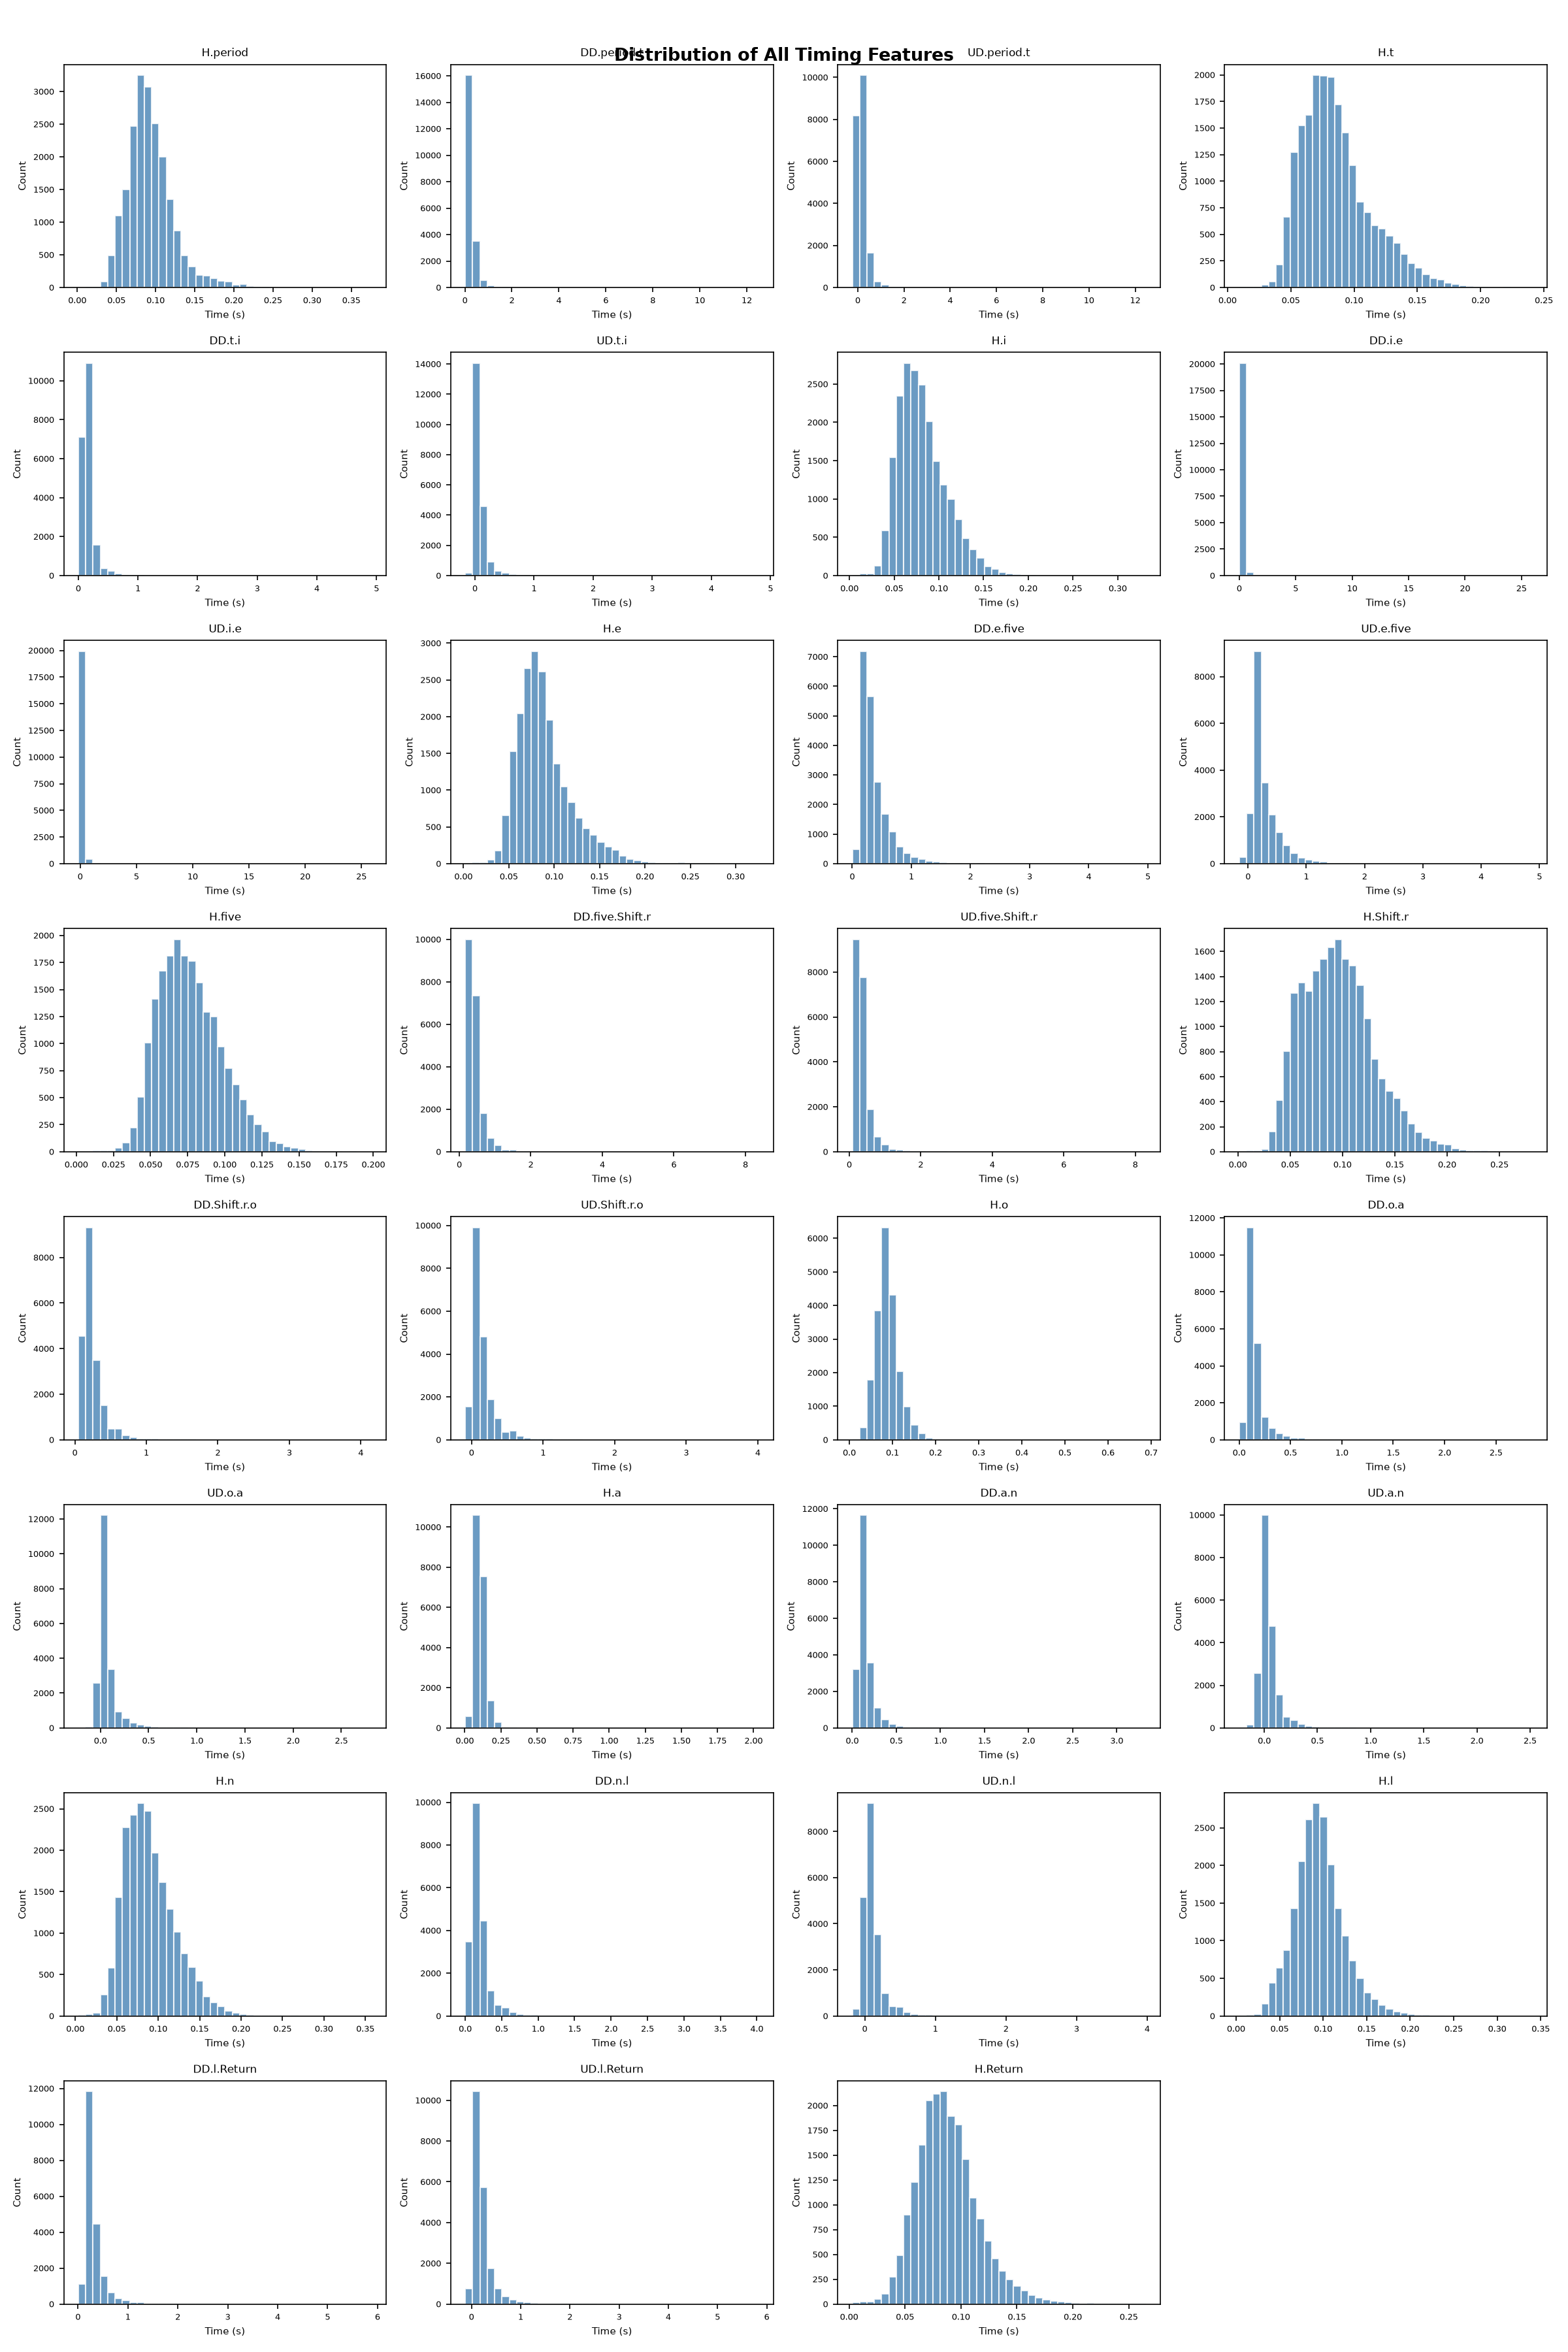

02_kde_plots.png


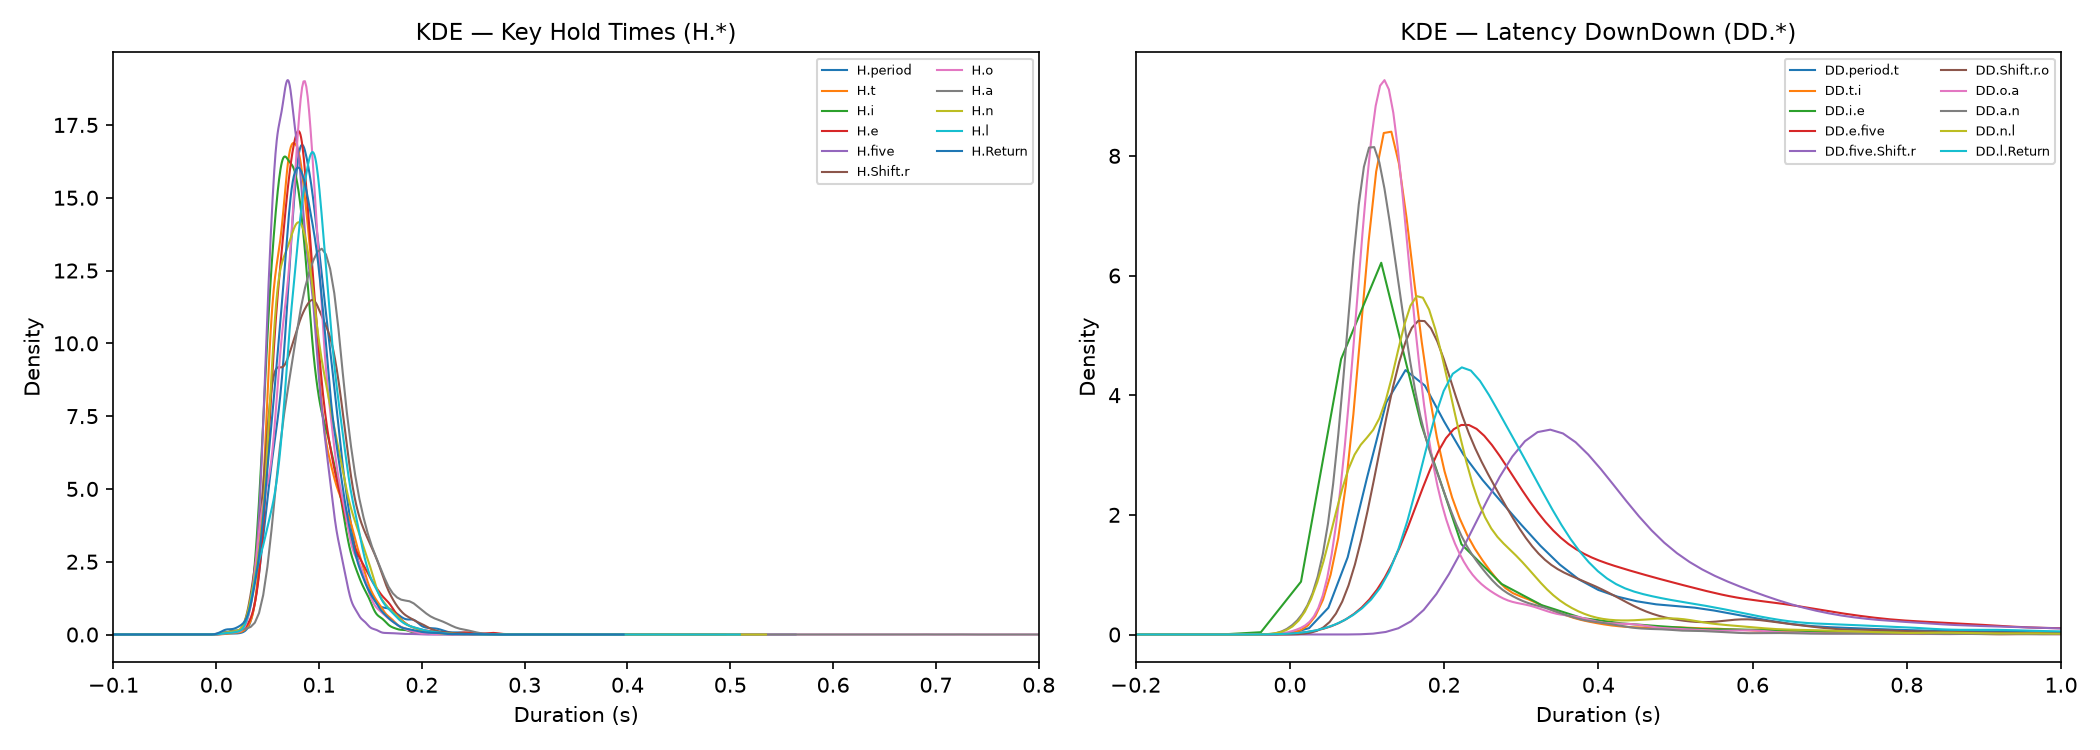

03_session_boxplots.png


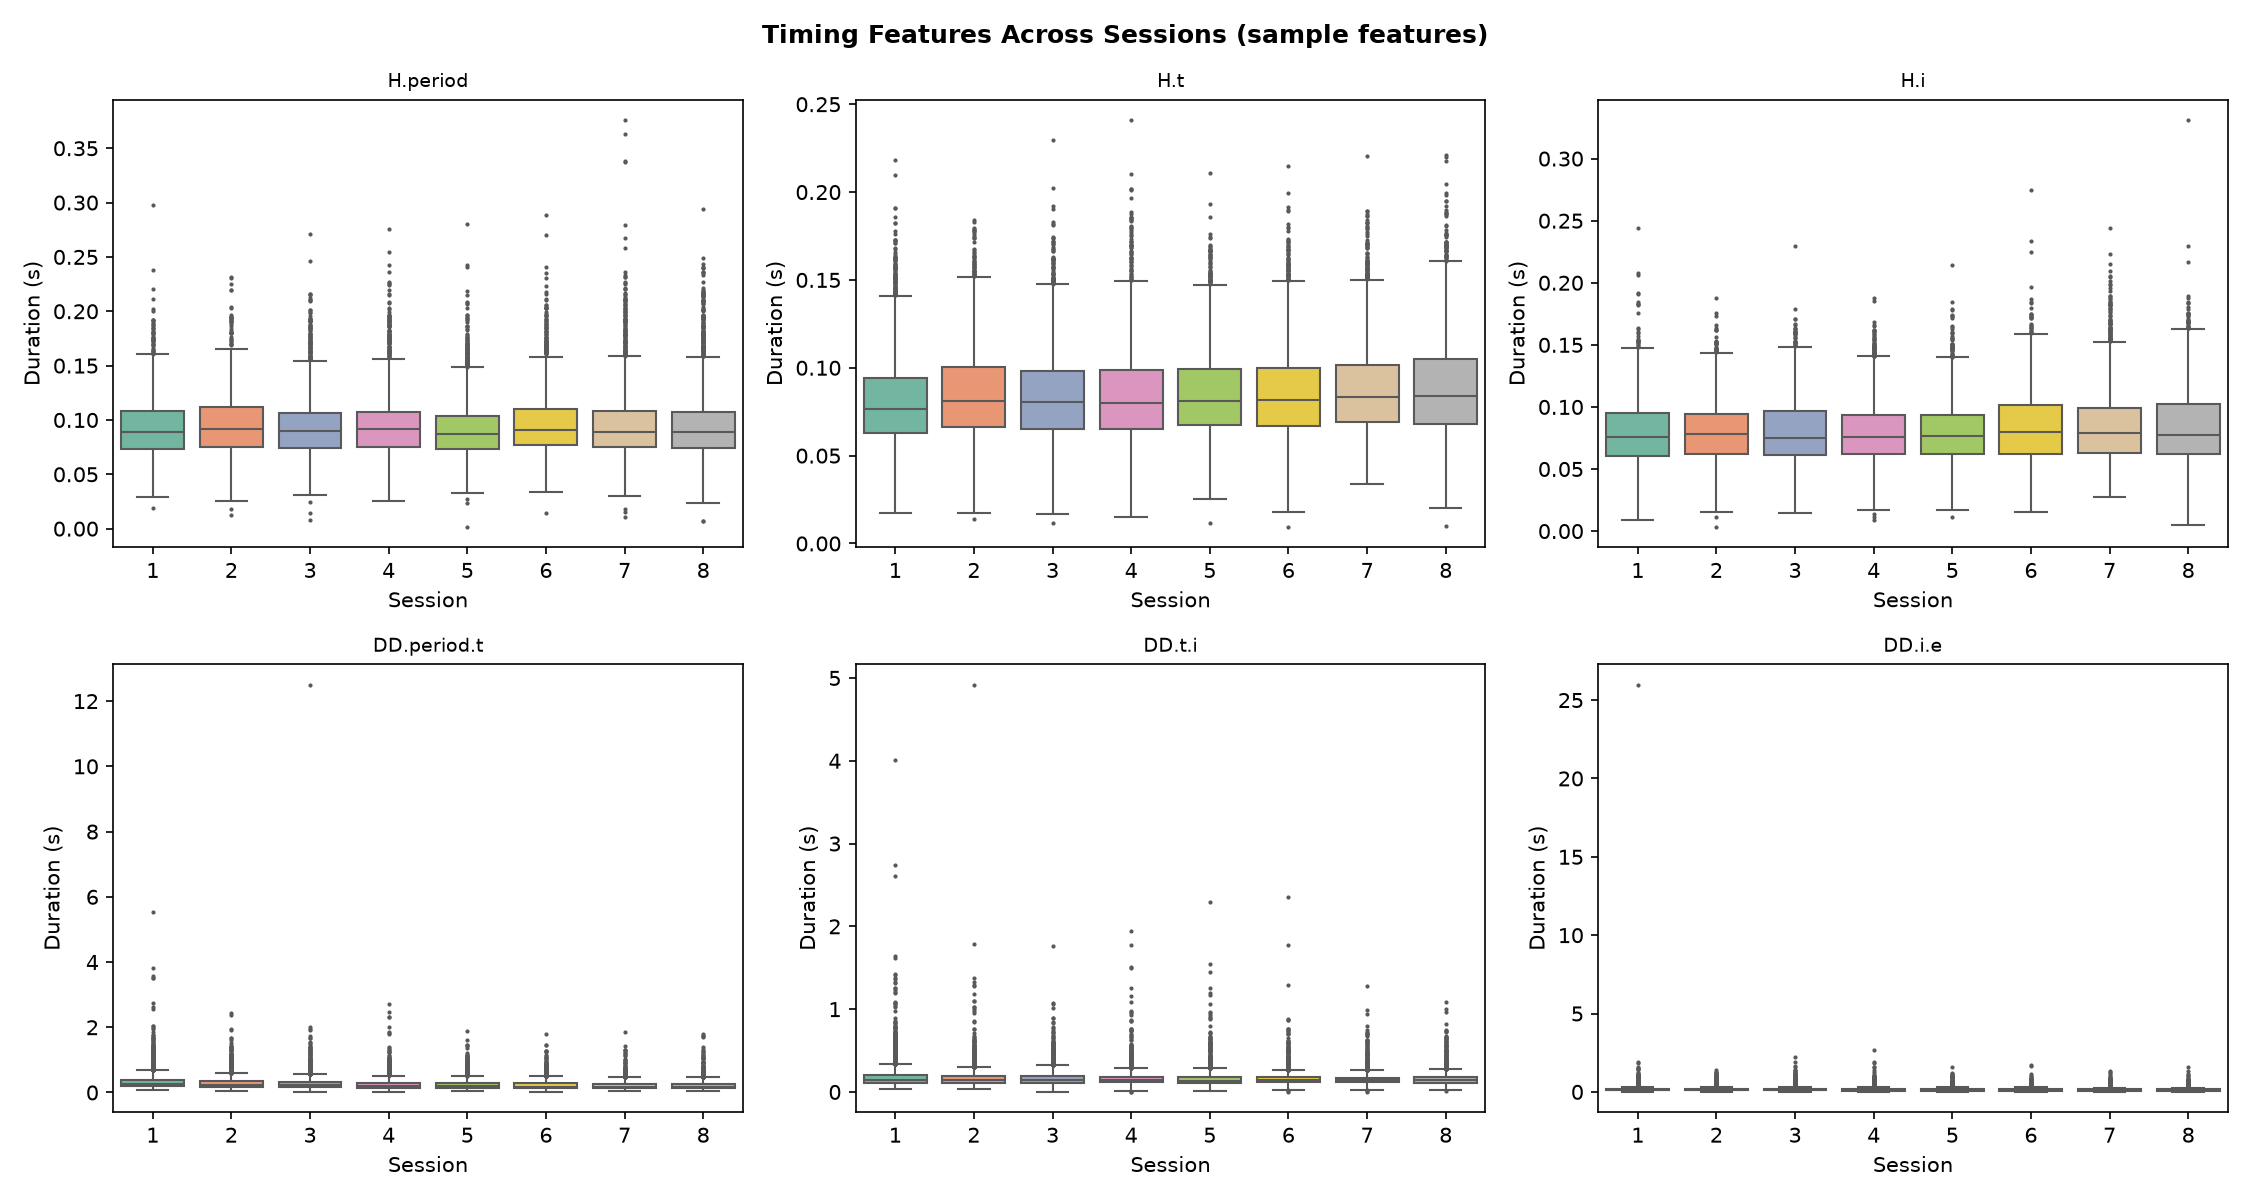

04_session_mean_hold.png


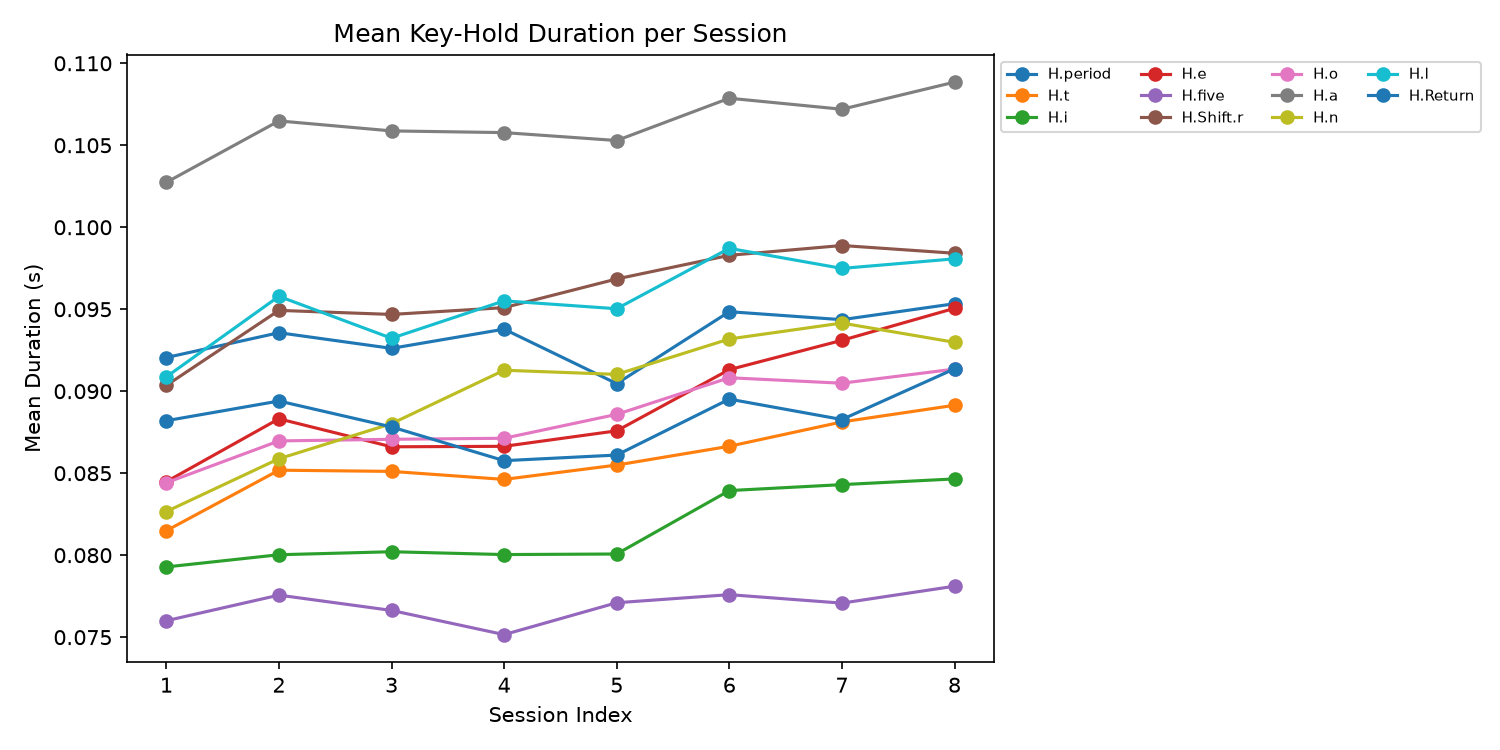

05_subject_variation.png


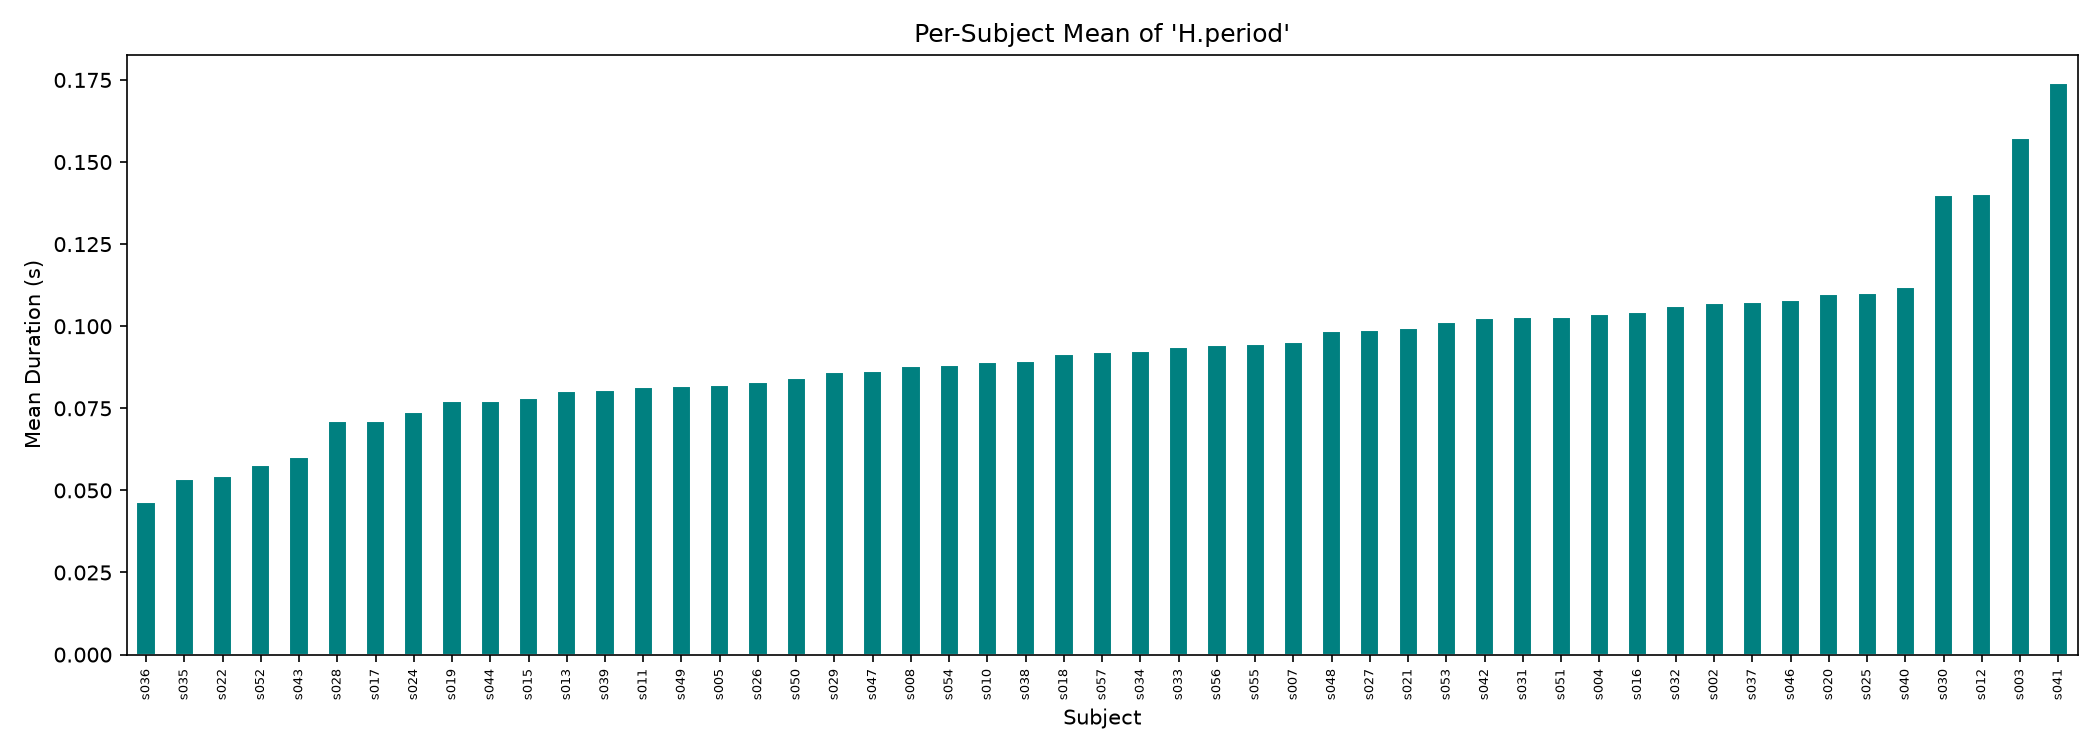

06_outlier_counts.png


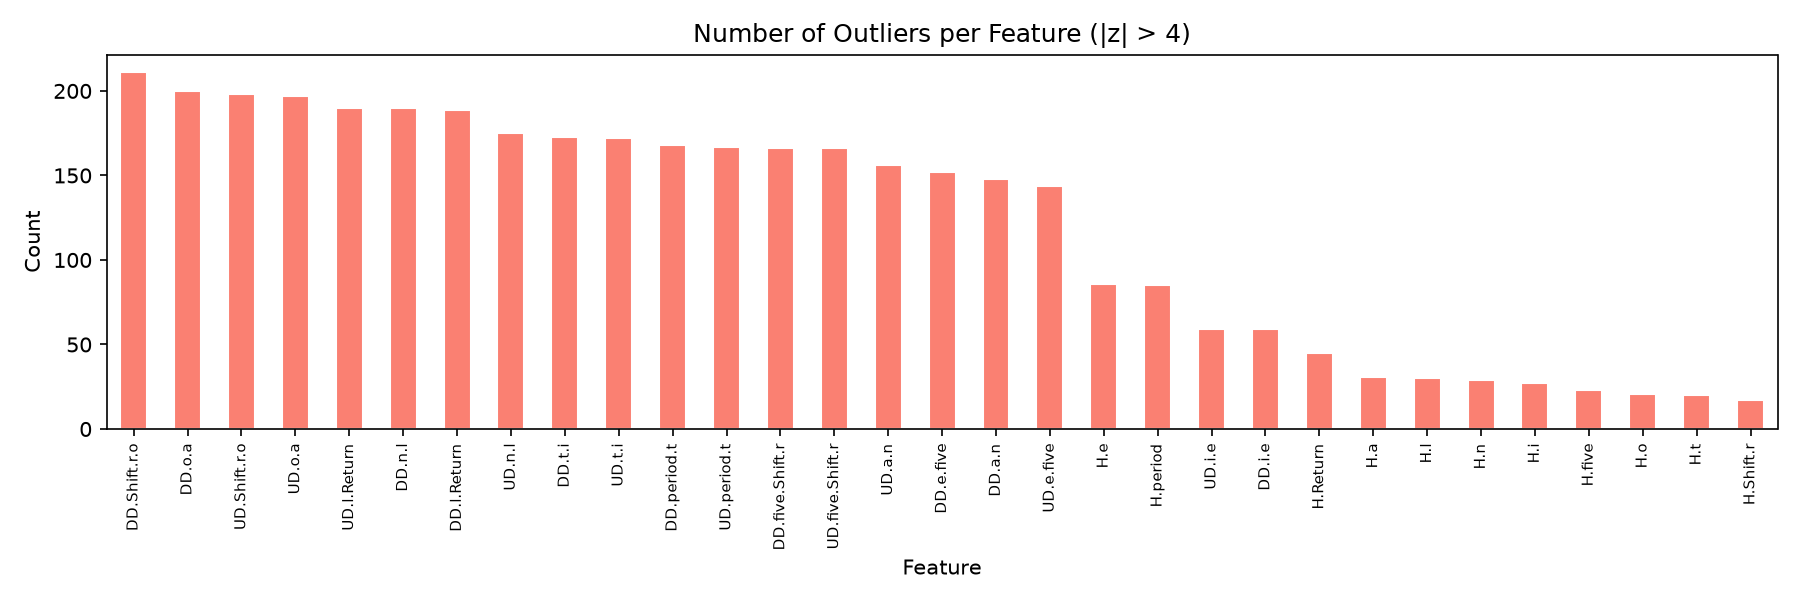

07_correlation_heatmap.png


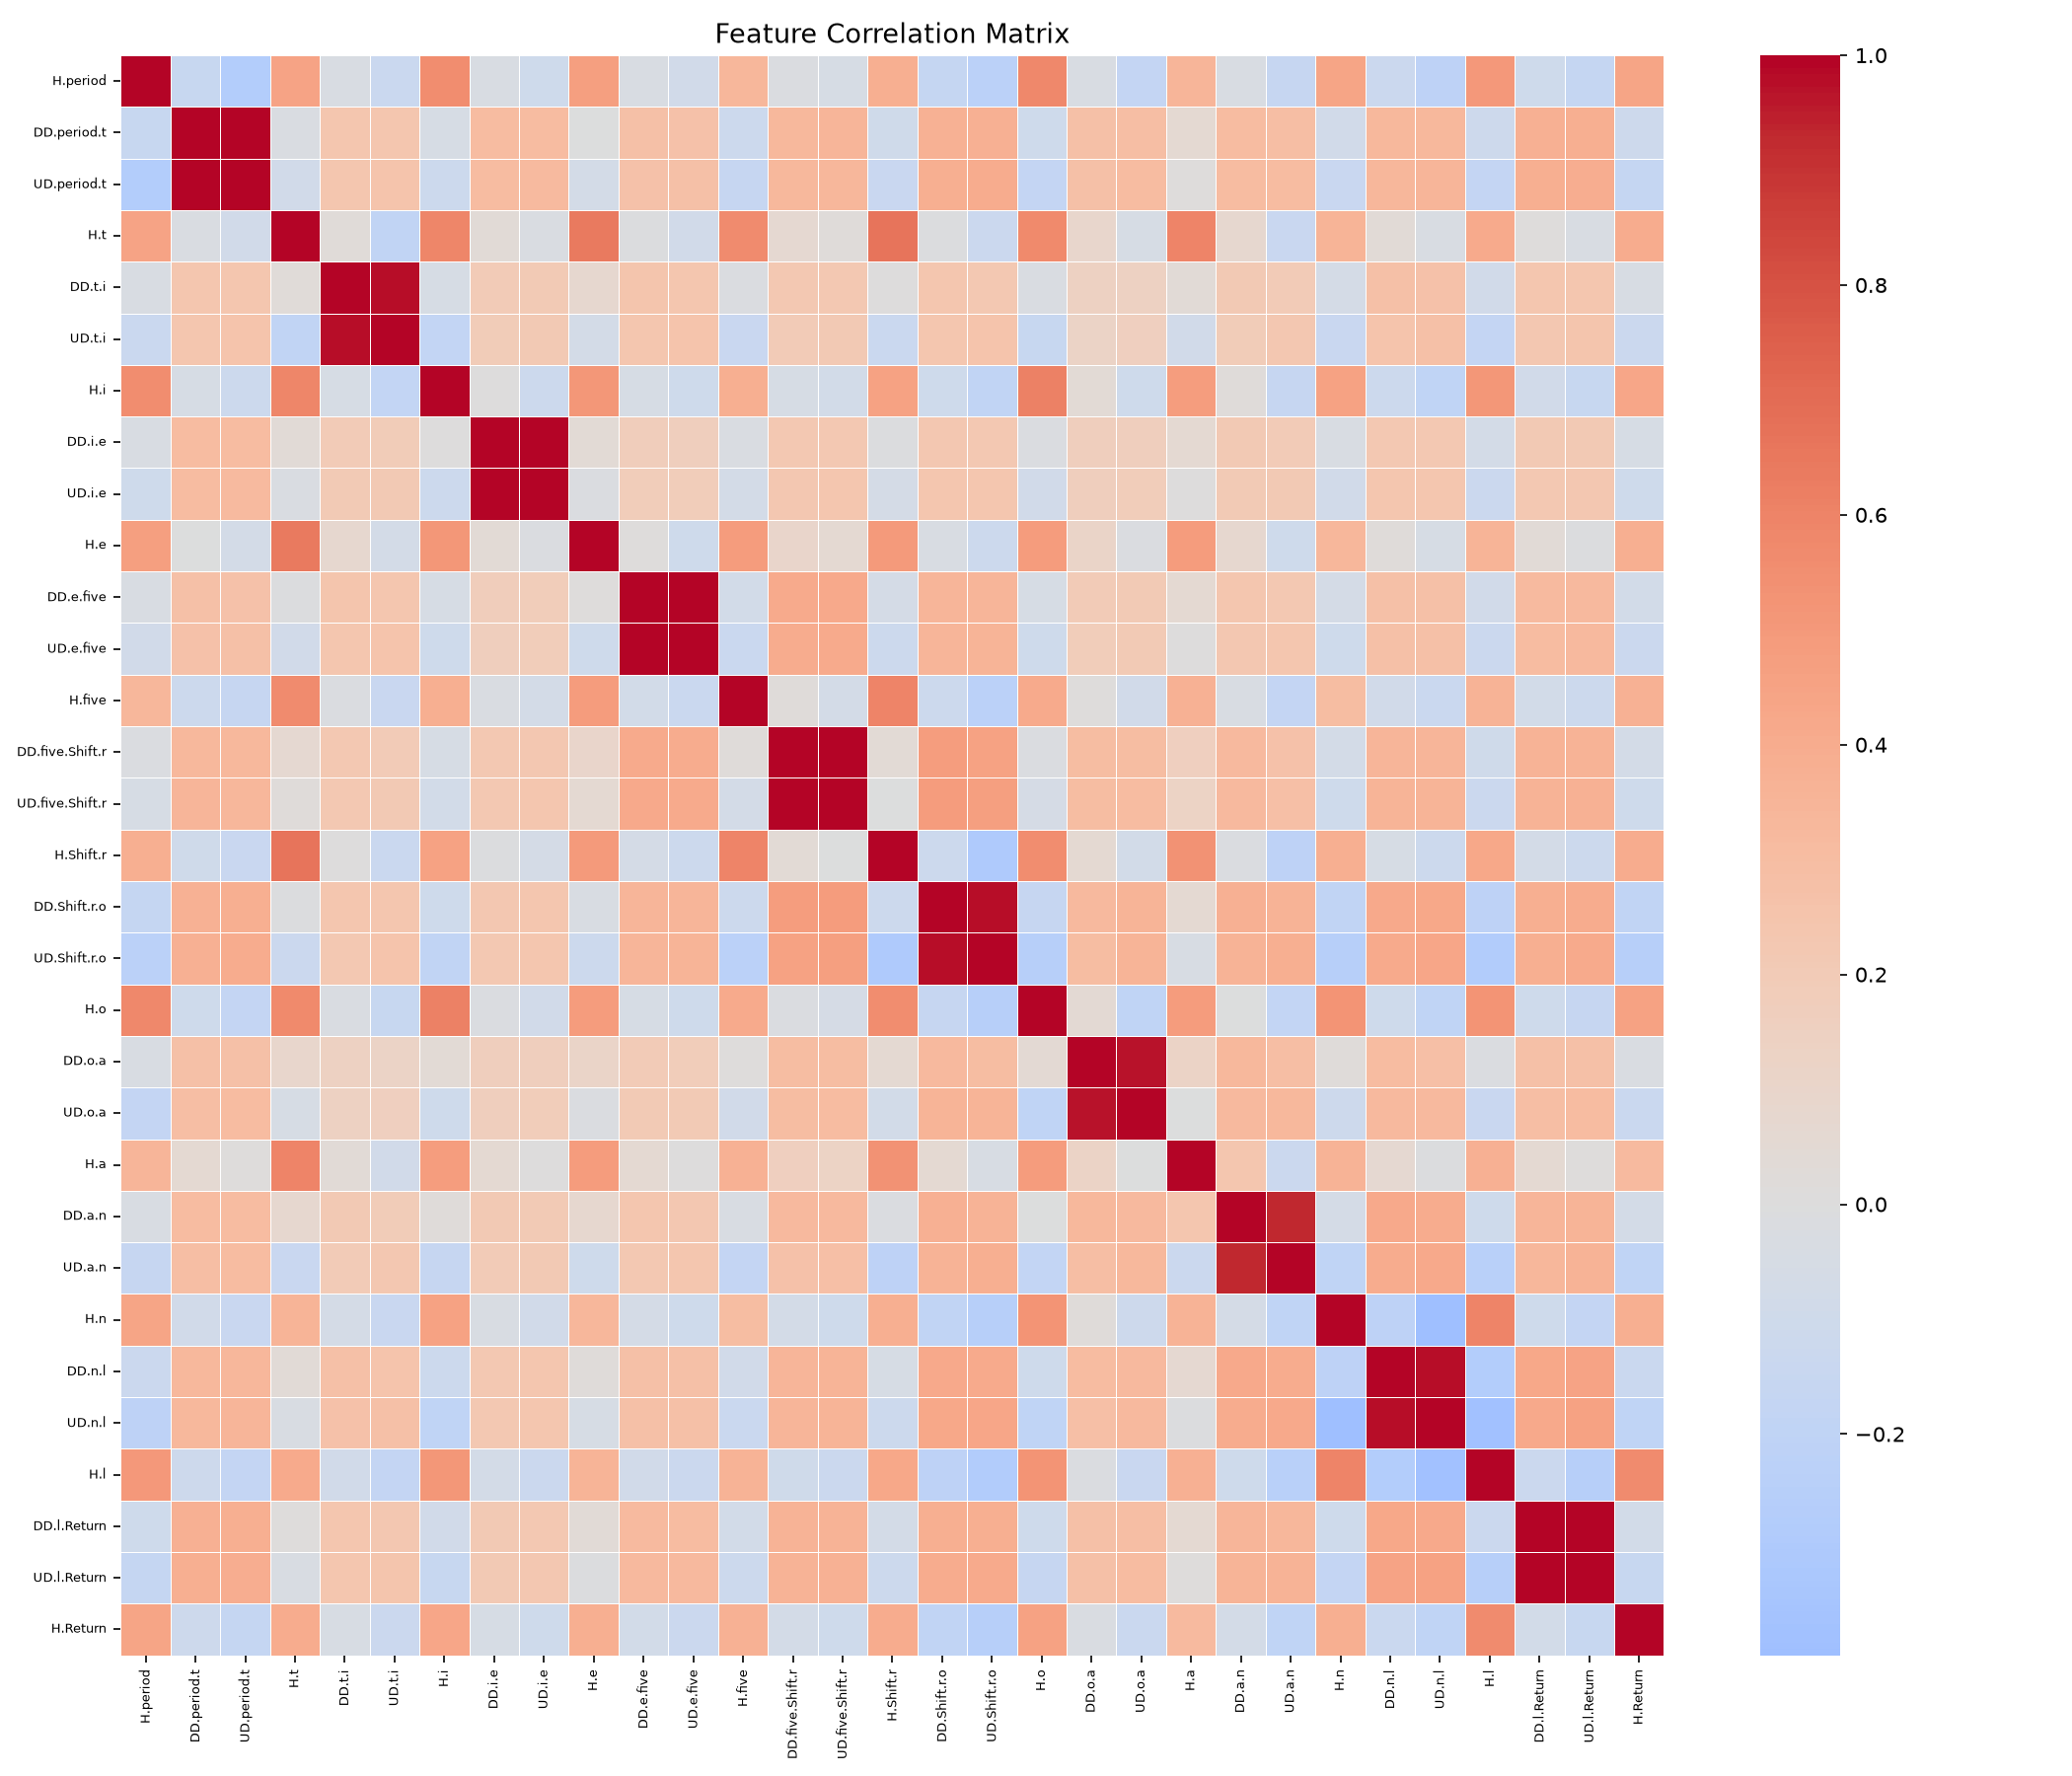

08_model_comparison.png


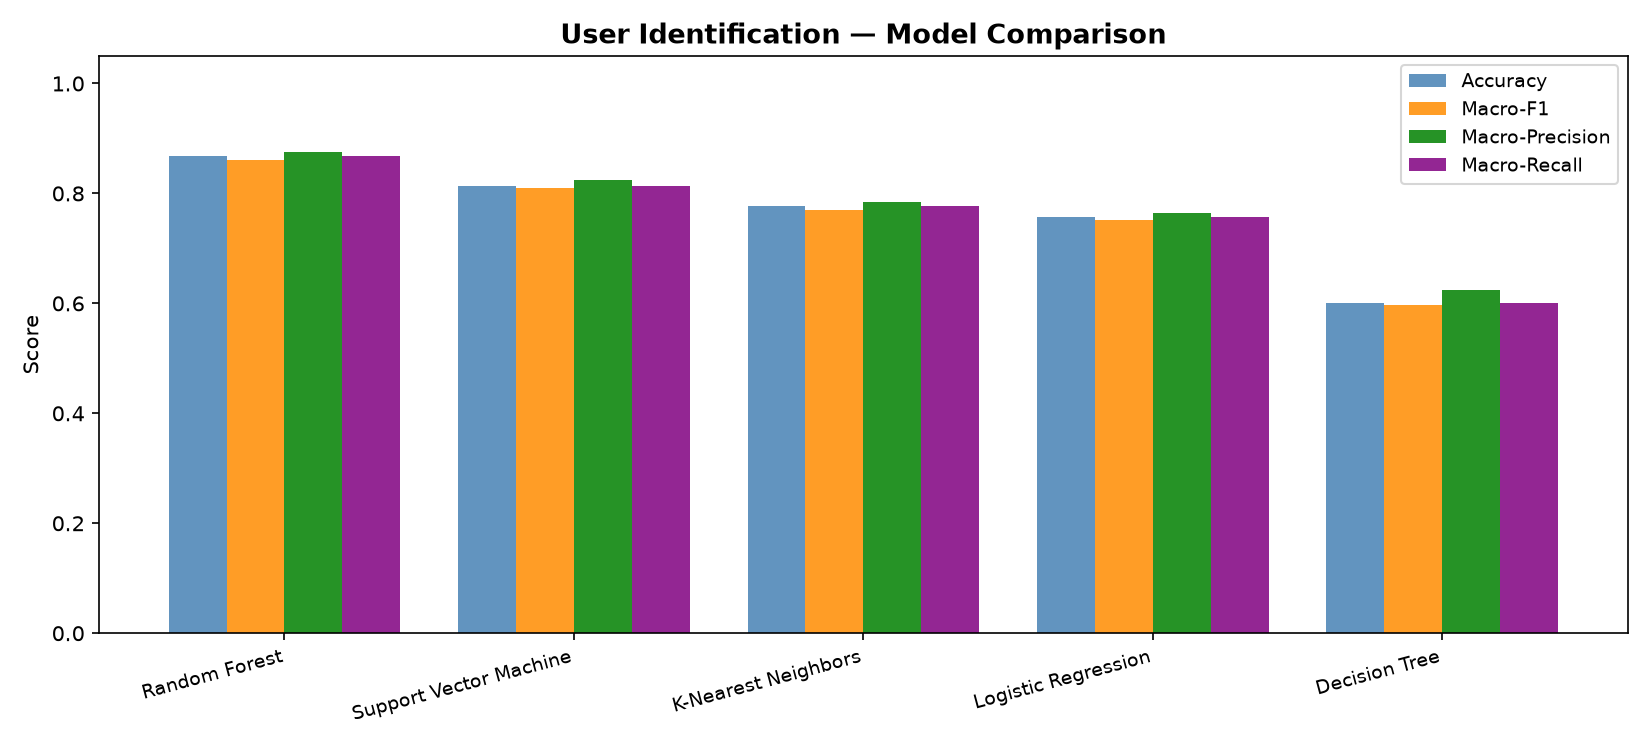

09_confusion_matrix.png


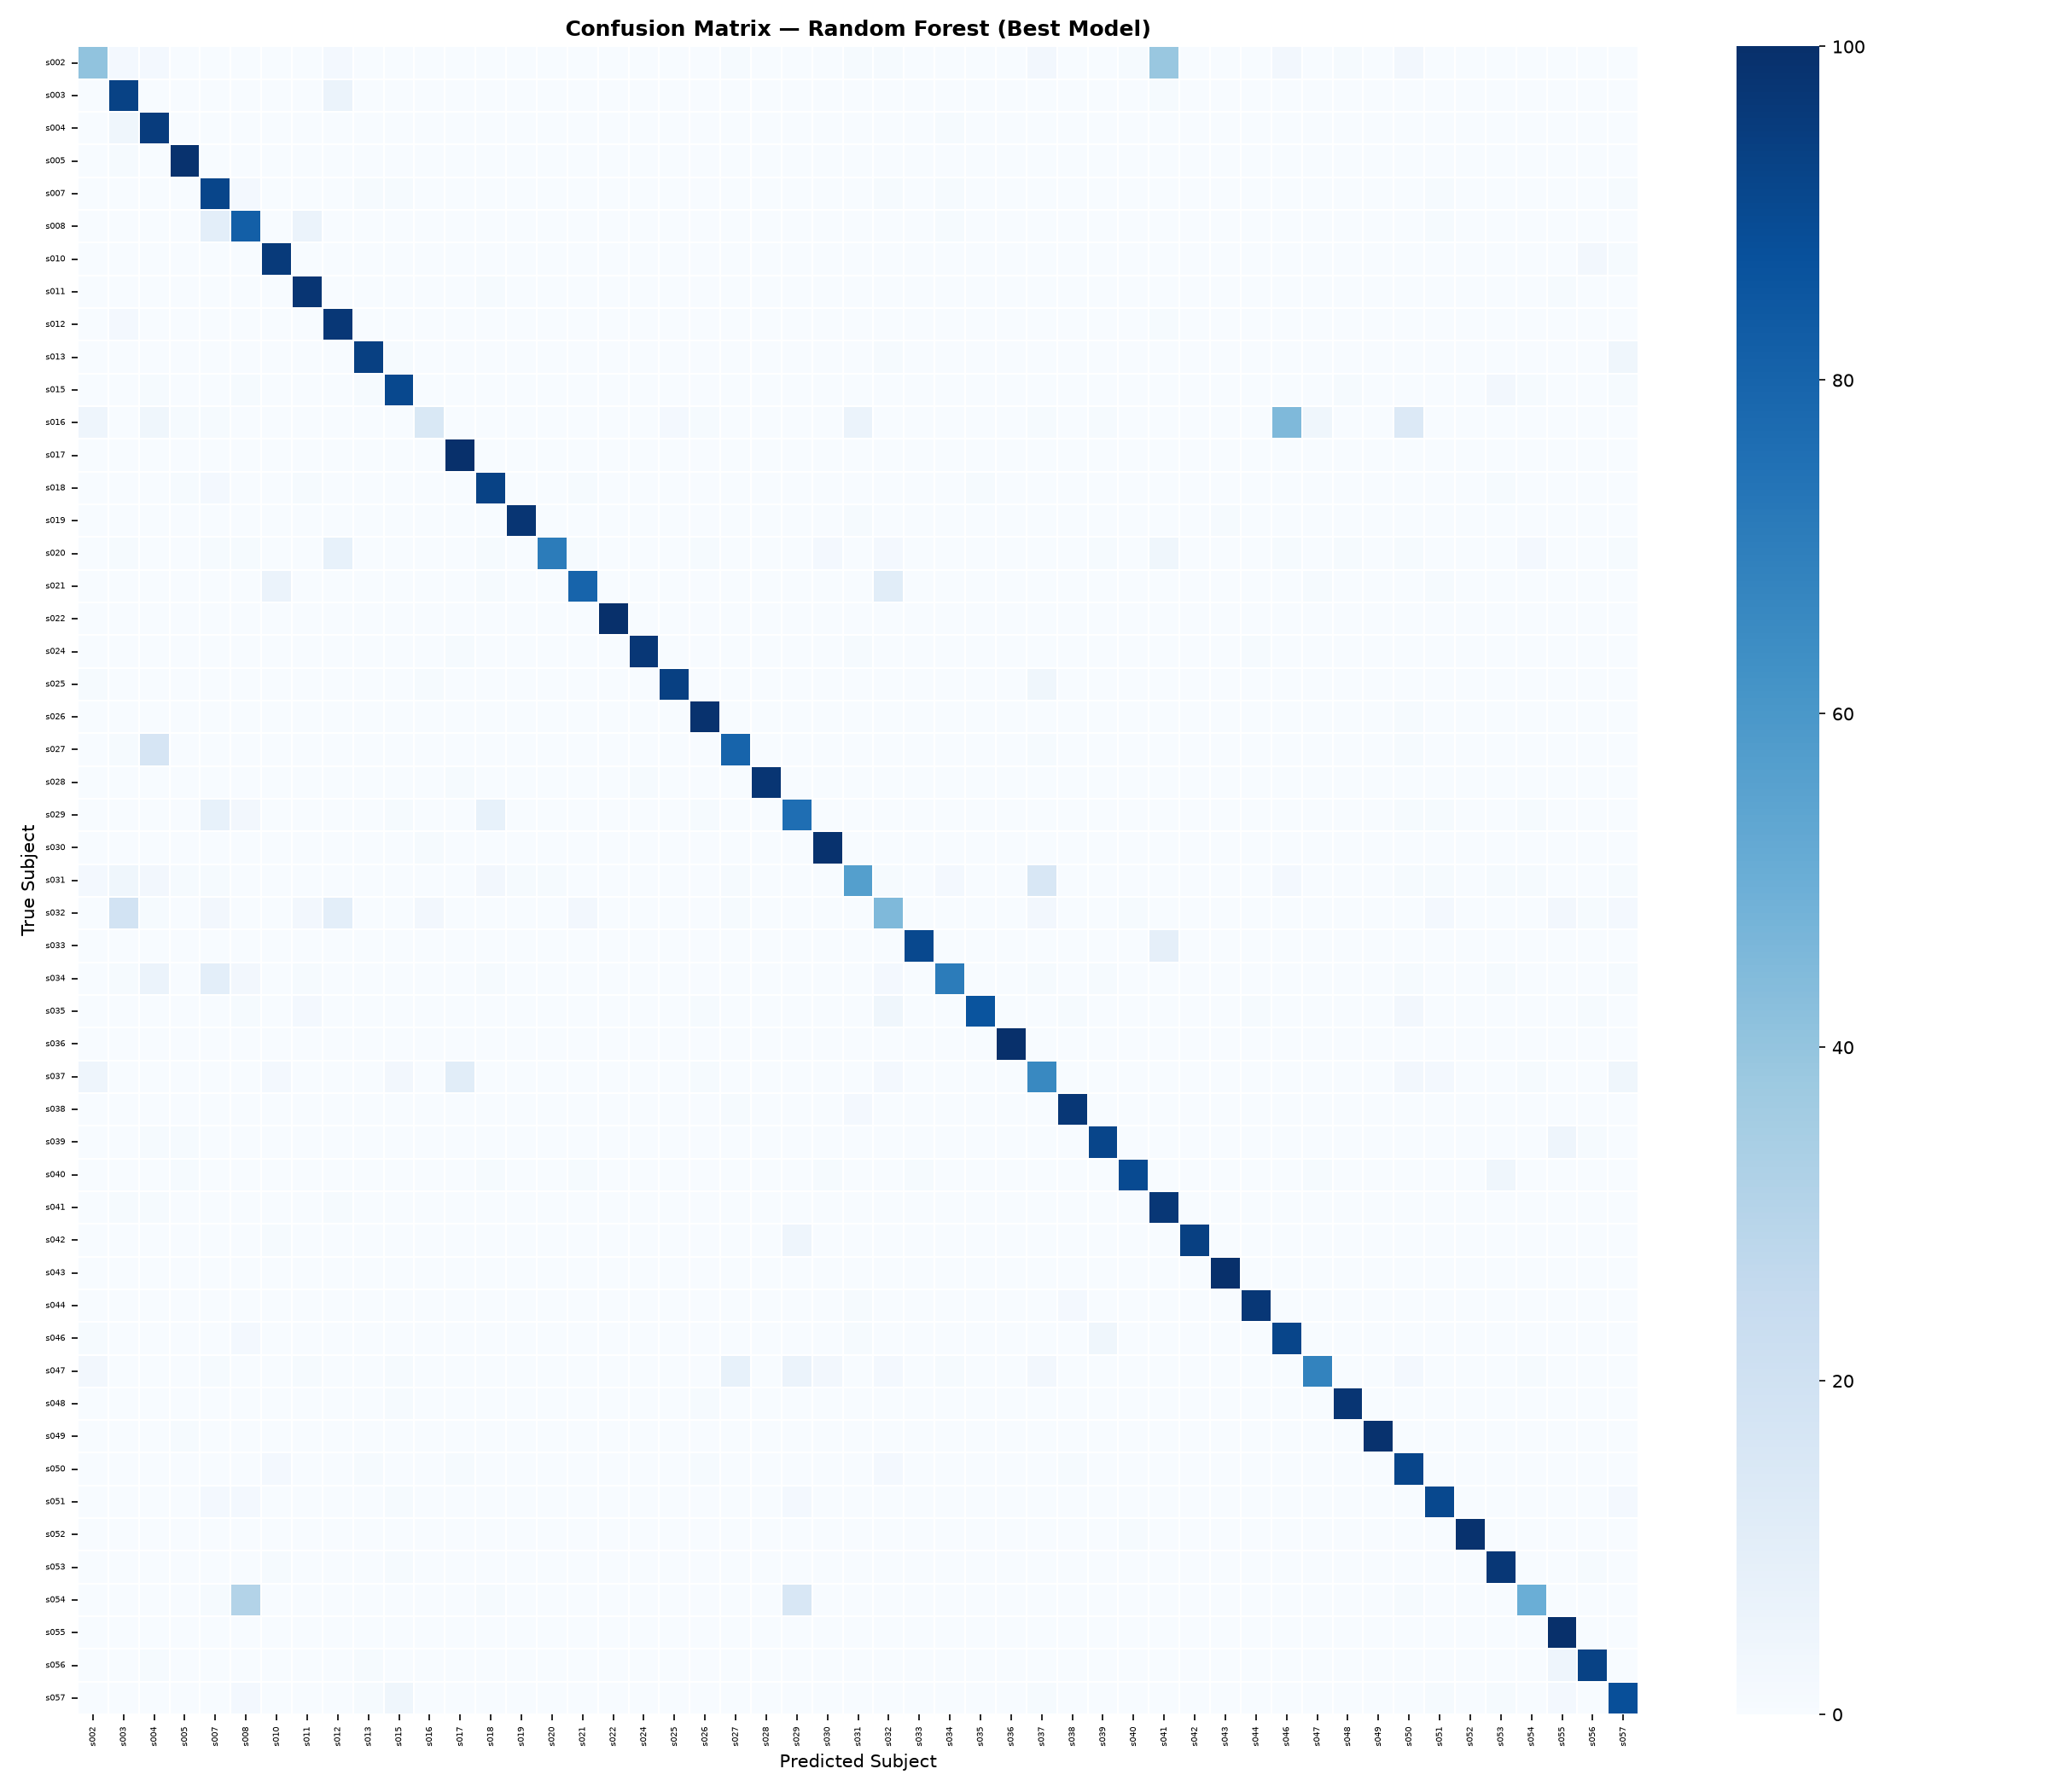

10_far_frr_per_subject.png


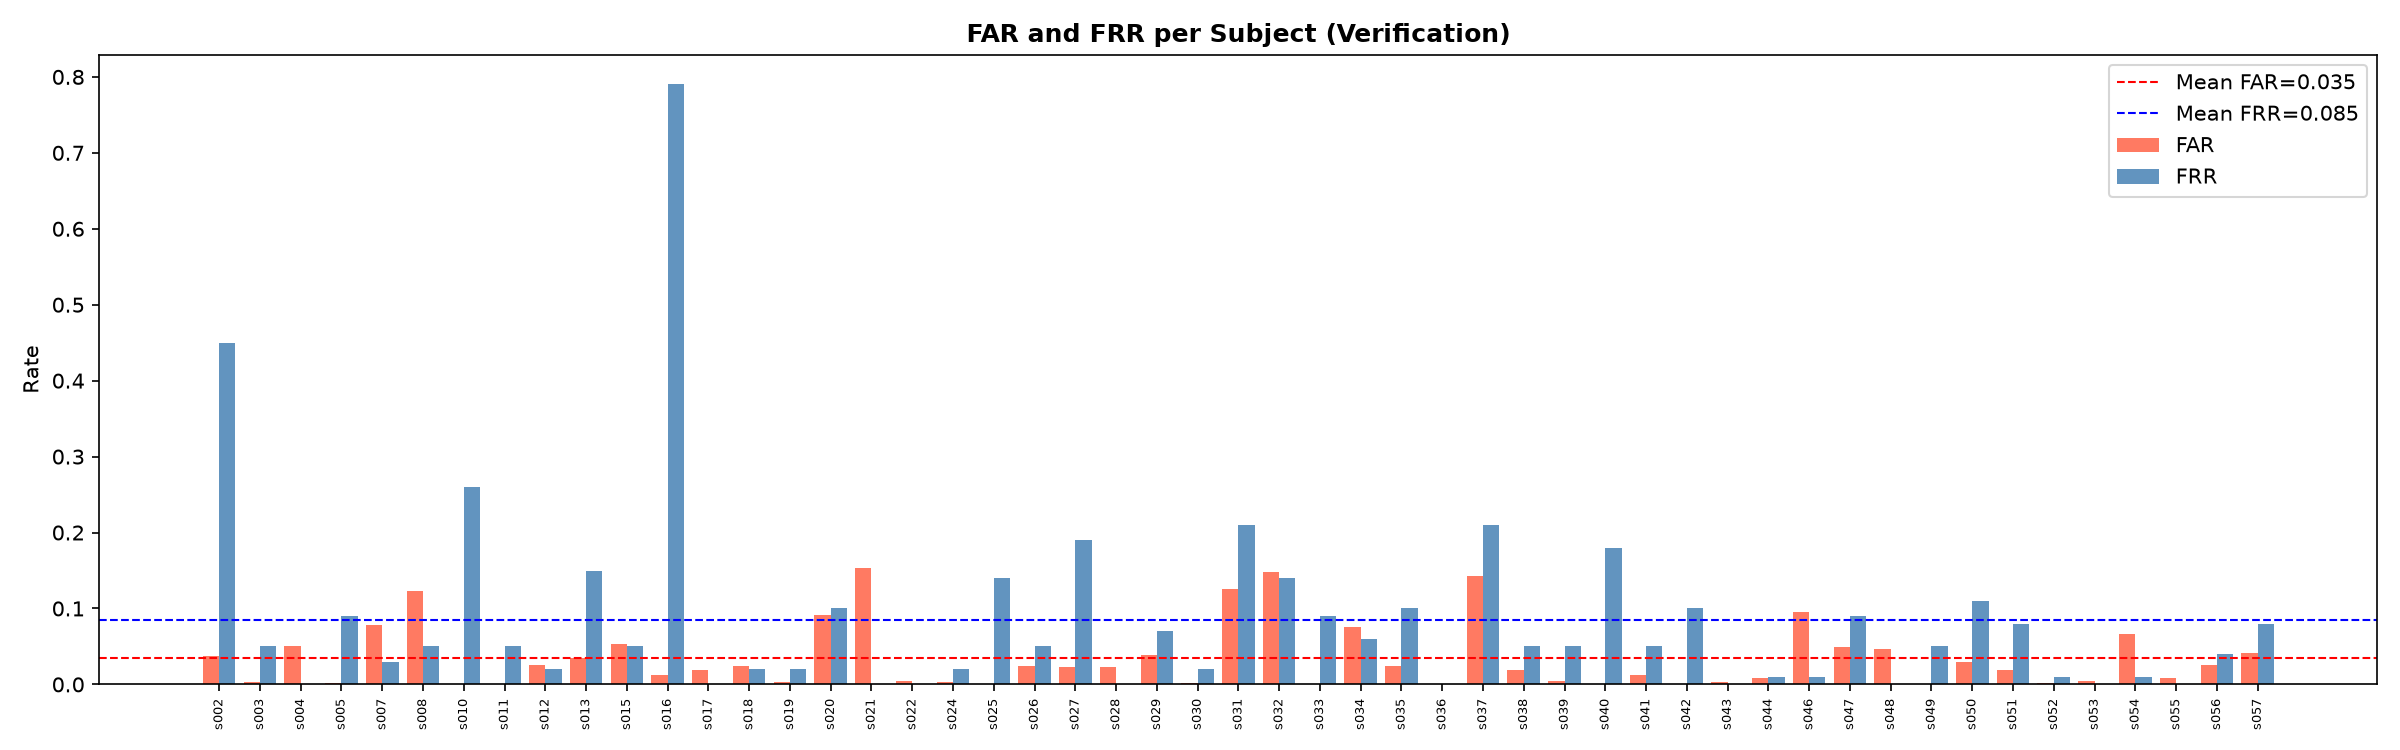

11_threshold_distribution.png


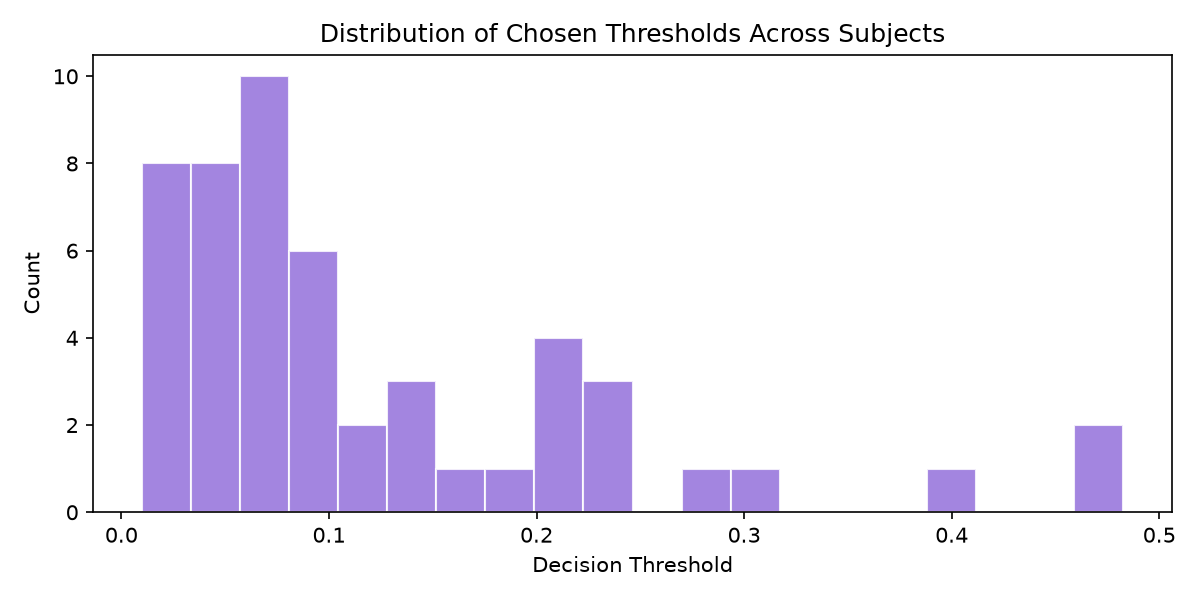

12_rf_mdi_importance.png


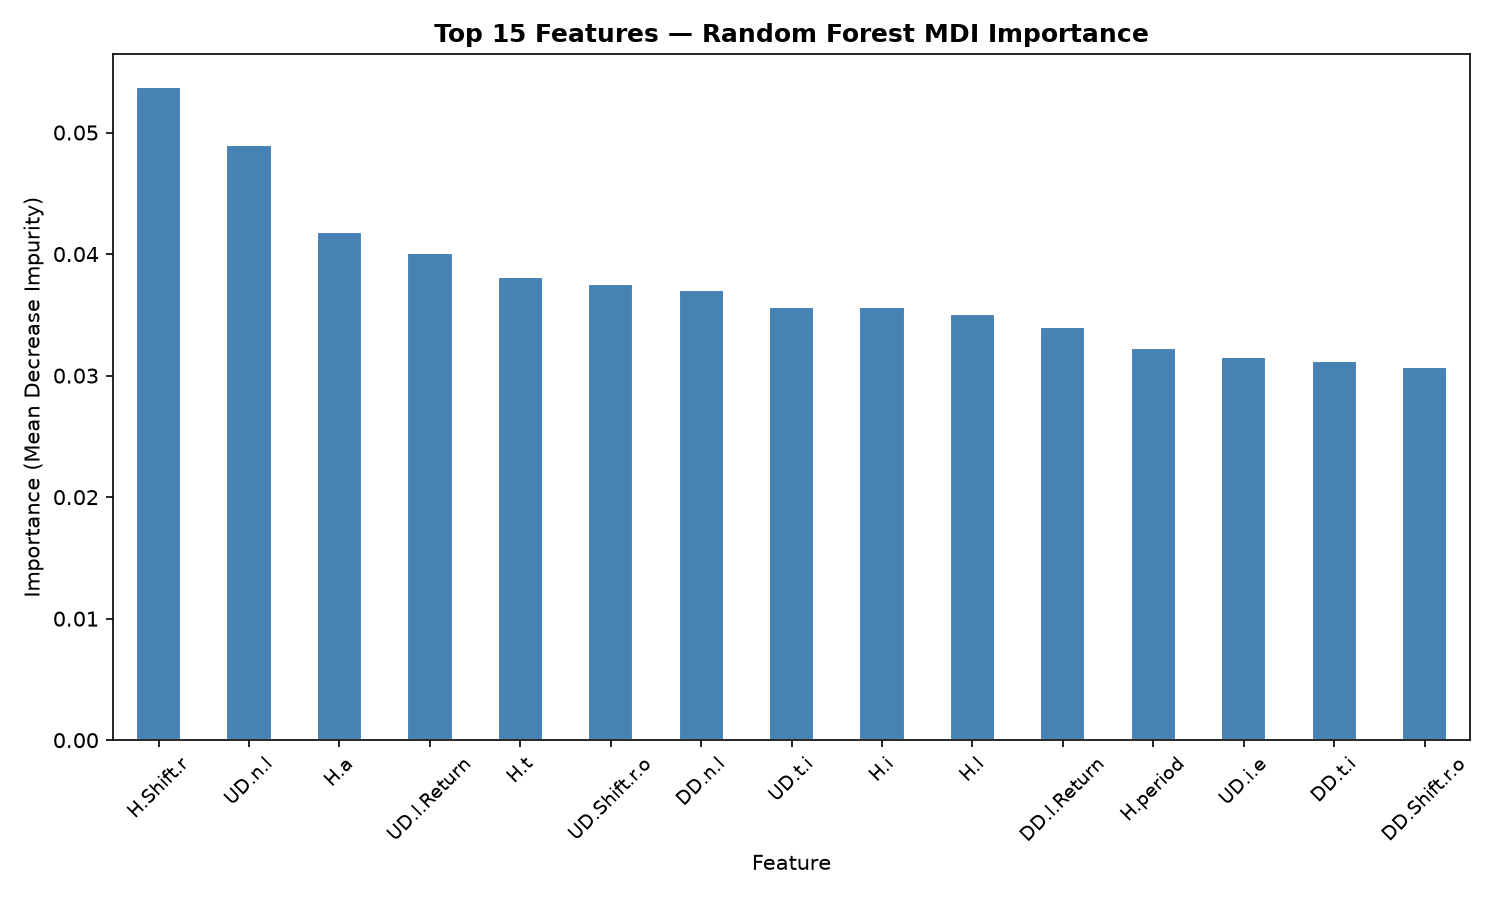

13_rf_mdi_all_features.png


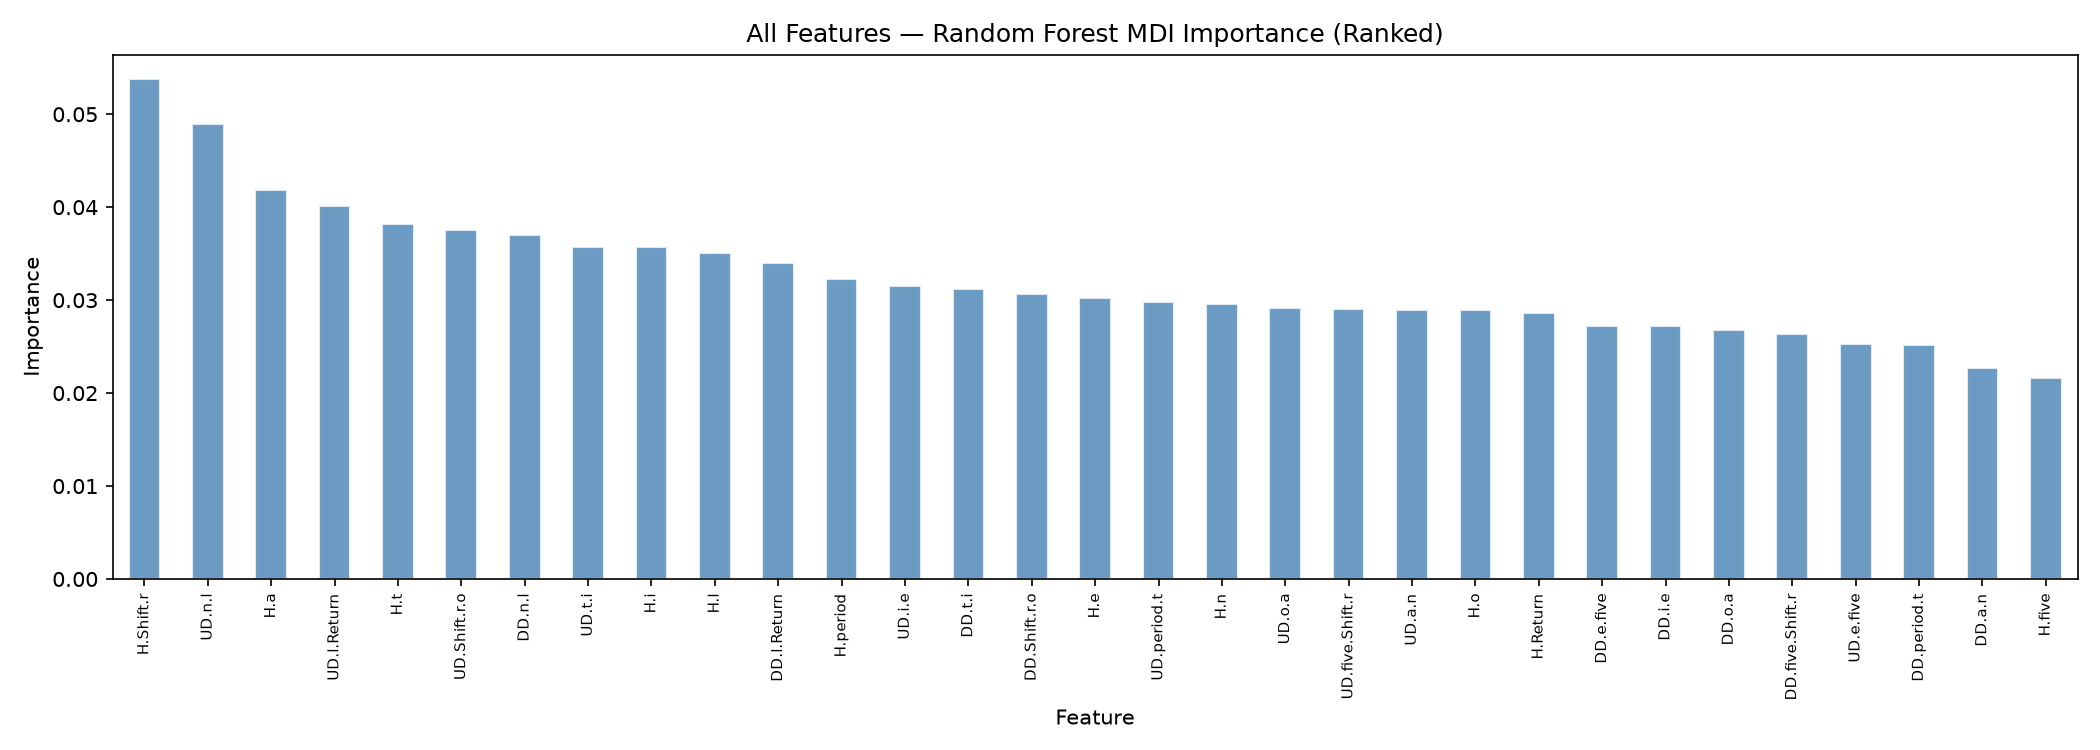

14_permutation_importance.png


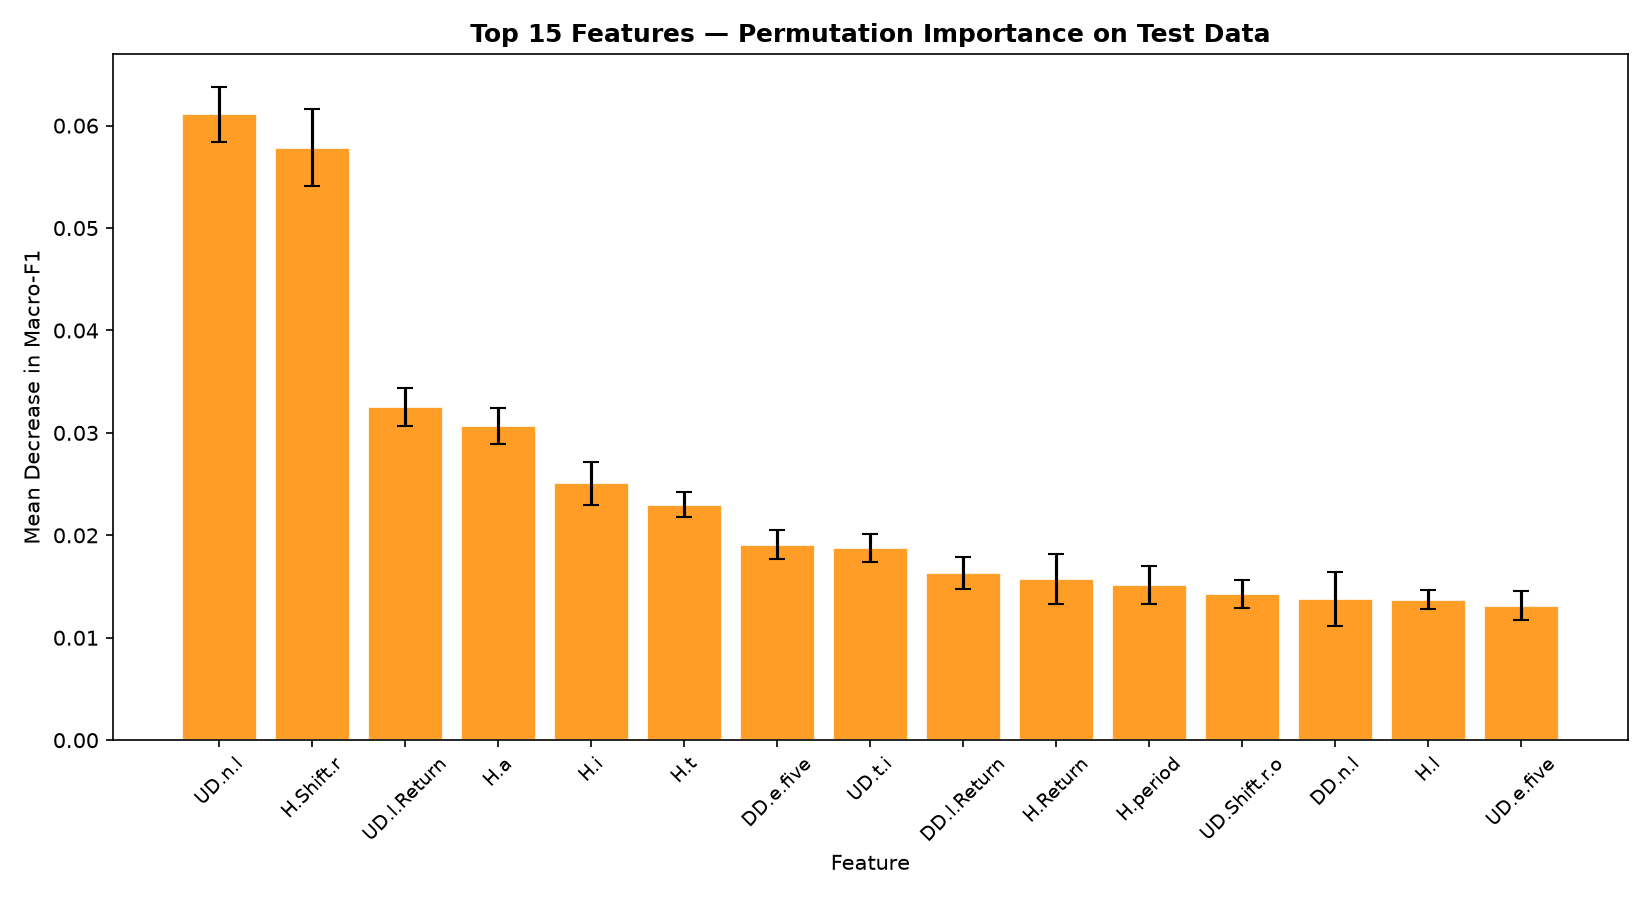

15_top_features_violin.png


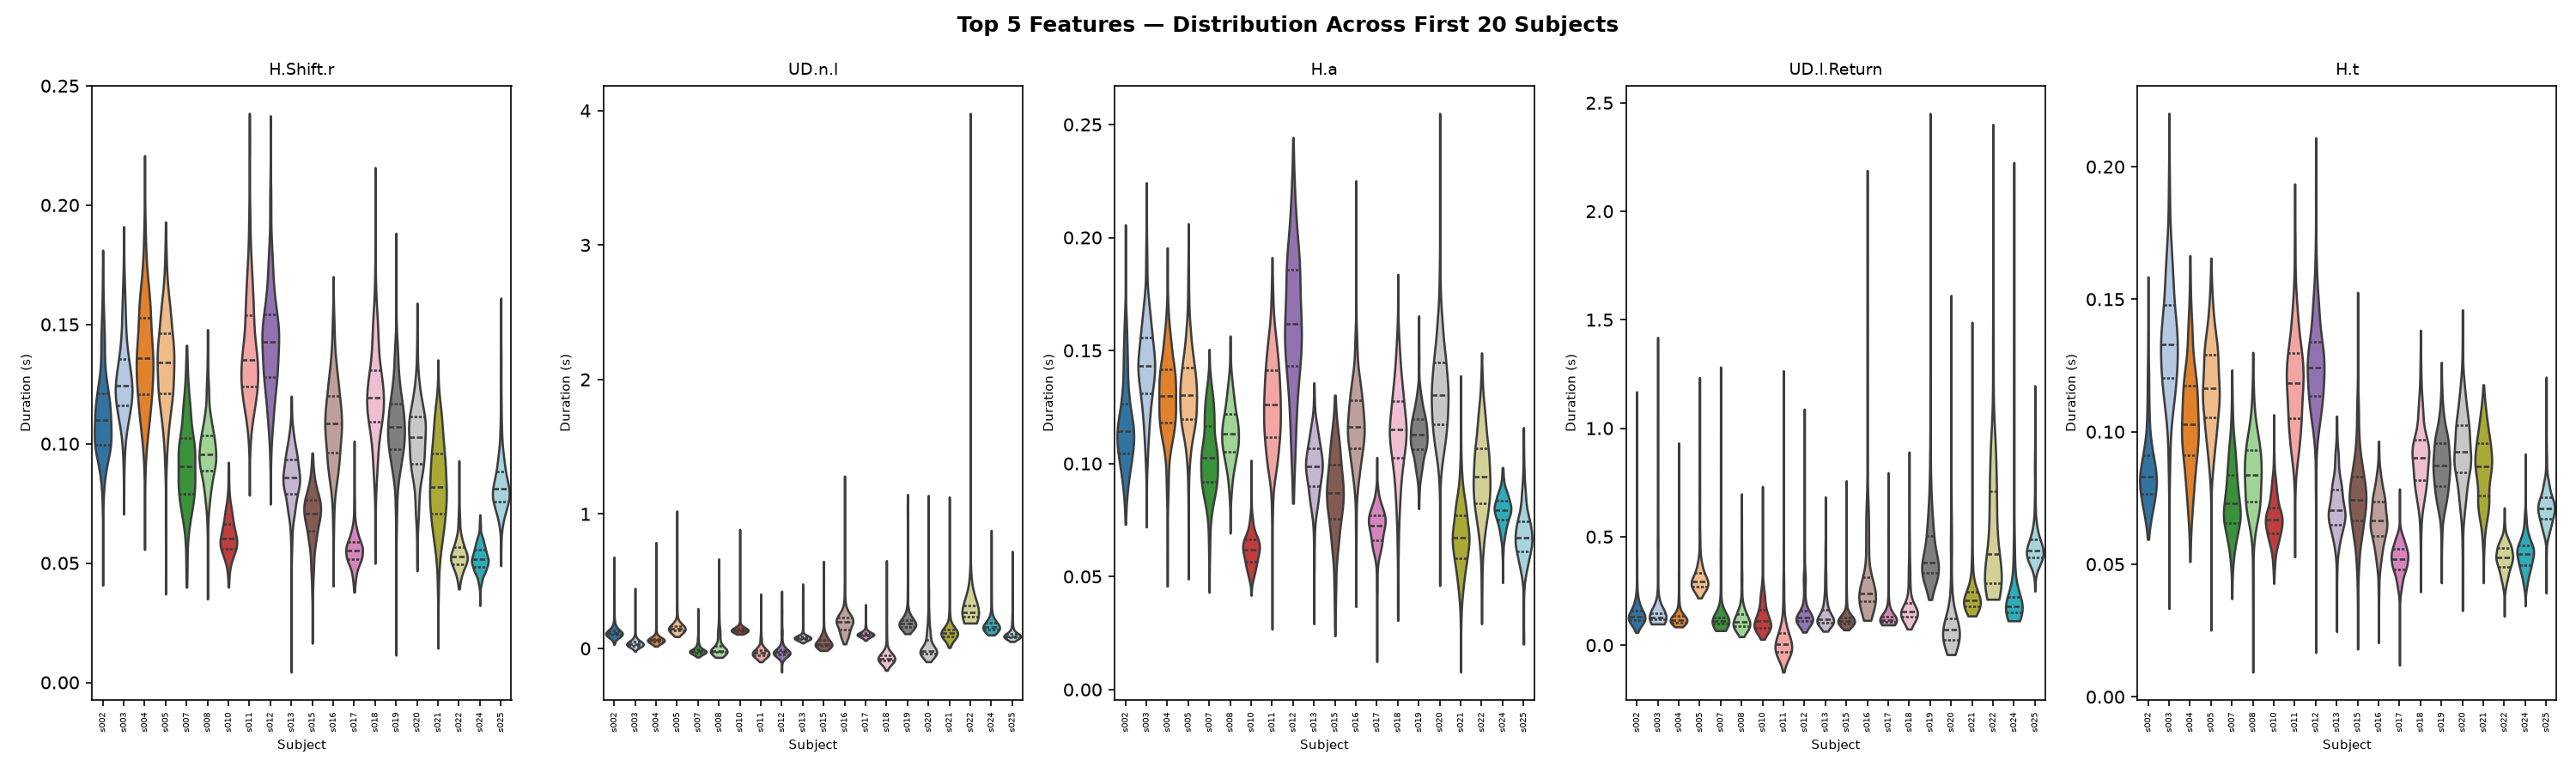

In [10]:
from IPython.display import display, Image
from pathlib import Path

graph_files = sorted(Path("outputs/graphs").glob("*.png"))

print("Total graphs:", len(graph_files))

for graph in graph_files:
    print(graph.name)
    display(Image(filename=str(graph)))